# Ames House Price Prediction

We use the final prediction combination from our project to estimate prices
for the competition test houses. Its recorded Kaggle log-RMSE is 0.11101.

Add the two inputs shown in the screenshot: Traindata and testData. Then run
all cells. We find the CSV files by their columns, so the dataset folder names
and capitalisation do not need to match a hard-coded path.

The saved predictions from five fitted model components are included below as
one CSV data table. We combine those predictions and apply the final
comparable-sale rule here. This notebook does not retrain those components.
It needs no extra dataset or download. The table is specific to the original
competition test houses.

The final output on Kaggle is /kaggle/working/submission.csv.

## 1. Import libraries

In [1]:
from pathlib import Path
from io import StringIO

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")

## 2. Read Traindata and testData

We look inside the attached inputs for one complete training CSV and one
complete test CSV. The training file contains SalePrice; the test file does
not. We preserve the literal category None when reading the files.

In [2]:
input_dir = Path("/kaggle/input")
output_dir = Path("/kaggle/working")

# These two lines also allow the notebook to run in the local project folder.
if not input_dir.exists():
    input_dir = Path("Dataset")
    output_dir = Path("kaggle_outputs")

output_dir.mkdir(parents=True, exist_ok=True)
train_files = []
test_files = []

for file_path in input_dir.rglob("*"):
    if file_path.suffix.lower() == ".csv":
        columns = pd.read_csv(file_path, nrows=0).columns
        if "Id" in columns and "GrLivArea" in columns and "SaleCondition" in columns:
            if "SalePrice" in columns:
                train_files.append(file_path)
            else:
                test_files.append(file_path)

if len(train_files) != 1 or len(test_files) != 1:
    raise ValueError("Attach one complete training CSV in Traindata and one complete test CSV in testData.")

train = pd.read_csv(train_files[0], keep_default_na=False, na_values=["", "NA"])
test = pd.read_csv(test_files[0], keep_default_na=False, na_values=["", "NA"])

print("Traindata:", train_files[0])
print("testData:", test_files[0])
print("Train shape:", train.shape, "Test shape:", test.shape)
display(train.head())

Traindata: Dataset/train.csv
testData: Dataset/test.csv
Train shape: (1460, 81) Test shape: (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [3]:
assert train.shape == (1460, 81)
assert test.shape == (1459, 80)
assert train["Id"].is_unique and test["Id"].is_unique
assert train["SalePrice"].notna().all()
assert train["SalePrice"].gt(0).all()

display(train.isna().sum().sort_values(ascending=False).head(10).to_frame("Missing values"))

,Missing values
PoolQC,1453
MiscFeature,1406
Alley,1369
Fence,1179
FireplaceQu,690
LotFrontage,259
GarageYrBlt,81
GarageCond,81
GarageType,81
GarageFinish,81


## 3. A brief look at the data

Taking logs makes the target less skewed. Prices usually rise with area and
quality, but two unusually large houses do not follow that pattern. We keep
those records and return to them in the comparable-sale check.

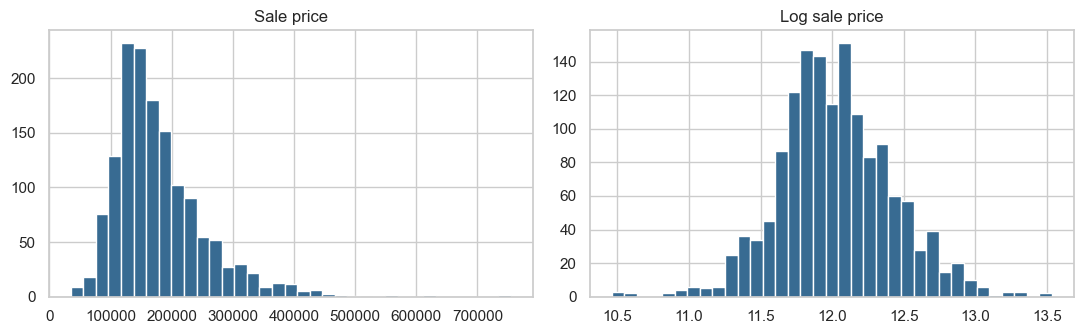

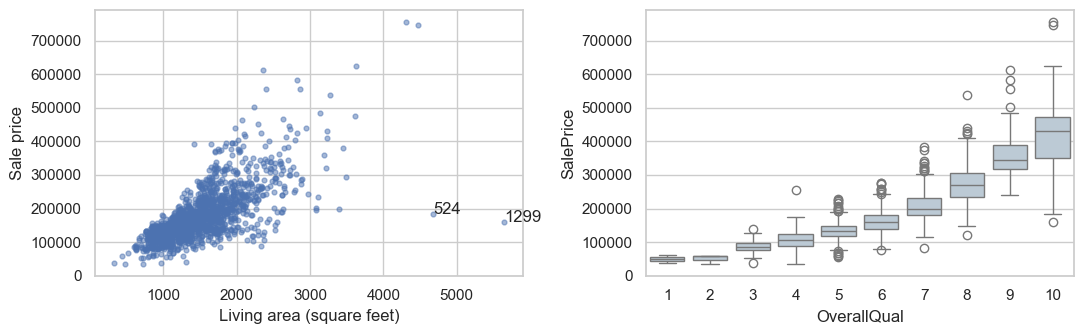

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(train["SalePrice"], bins=35, color="#386B92")
axes[0].set_title("Sale price")
axes[1].hist(np.log(train["SalePrice"]), bins=35, color="#386B92")
axes[1].set_title("Log sale price")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].scatter(train["GrLivArea"], train["SalePrice"], s=12, alpha=0.5)
axes[0].set_xlabel("Living area (square feet)")
axes[0].set_ylabel("Sale price")
for house_id in [524, 1299]:
    house = train.loc[train["Id"] == house_id].iloc[0]
    axes[0].annotate(str(house_id), (house["GrLivArea"], house["SalePrice"]))
sns.boxplot(data=train, x="OverallQual", y="SalePrice", ax=axes[1], color="#b8cbd9")
plt.tight_layout()
plt.show()

## 4. Saved component predictions

This cell contains the five saved model outputs as ordinary CSV data. It is
included so that only Traindata and testData need to be attached on Kaggle.
The numerical columns are log predictions for stacking, TabICLv2 and Kumo,
and price predictions for SVM and the SVR/CatBoost correction branch.

We match the table to test Id before combining predictions. The model inputs
were processed in the original training runs; filling the raw test data again
would not retrain or change these saved outputs.

In [5]:
component_predictions = pd.read_csv(StringIO("""
Id,stack_log,svm_price,correction_price,tabicl_log,kumo_log
1461,11.705801671665213,120520.290276056,122621.60557296642,11.731760025024414,11.715128421783447
1462,11.968148686863206,174808.712924048,161442.14278438775,11.98909854888916,11.98996353149414
1463,12.113536249722884,188323.954623179,185143.80431521146,12.157535552978516,12.143679141998291
1464,12.165954636514034,199985.914570064,198076.62471687183,12.190160751342773,12.203221797943115
1465,12.169640395290868,185657.43680406,188963.27494049436,12.097455024719238,12.105819702148438
1466,12.051340606911625,174841.535809656,171508.28360654213,12.08928394317627,12.086704730987549
1467,12.04750637506502,185791.873383307,174862.39732355953,12.079691886901855,12.083436489105225
1468,11.987569269278051,165601.055842786,163336.4072463658,12.029857635498047,12.037556648254395
1469,12.16465591052448,192440.236706408,185609.43452115674,12.116137504577637,12.112643241882324
1470,11.704616883207587,128279.770179178,127328.89407614381,11.732173919677734,11.745794773101807
1471,12.141888532529036,187946.297068827,188949.0146657927,12.155282974243164,12.162590026855469
1472,11.448450789801605,101664.415948987,96197.32014087305,11.456073760986328,11.476025581359863
1473,11.425898874573711,103677.503039011,95286.98654170326,11.517290115356445,11.50072193145752
1474,11.871833443679515,143504.487075451,148433.28775682105,11.919687271118164,11.908541202545166
1475,11.618240694951677,108035.307933368,115403.87199799599,11.656368255615234,11.626772403717041
1476,12.805147234612235,363790.621322738,378630.3986640327,12.81364917755127,12.827653884887695
1477,12.437242883583702,258032.823212525,258659.00153567755,12.439947128295898,12.454895973205566
1478,12.572692705202318,285828.061517463,281102.9052870241,12.55138111114502,12.52843952178955
1479,12.545852026344,289546.472825174,276904.27342254604,12.536407470703125,12.523822784423828
1480,13.133292389754889,468370.297044184,481522.6673388194,13.138087272644043,13.157200813293457
1481,12.68722819252851,325796.896313204,336801.6811759145,12.716373443603516,12.707939147949219
1482,12.246135250064333,206314.508189647,207833.2120694121,12.237238883972168,12.235229969024658
1483,12.096542268920874,183146.021113011,175162.44864548146,12.08887004852295,12.100649356842041
1484,11.97716095618778,163854.656582433,163106.24984443747,12.00526237487793,12.00958251953125
1485,12.106680871303842,181530.27384467,184663.045467595,12.077152252197266,12.110503673553467
1486,12.18287899099525,194149.419726123,195881.55916561495,12.171589851379395,12.177934169769287
1487,12.716791493545085,324347.209988636,339749.42462060275,12.632028579711914,12.676125526428223
1488,12.368685336351769,239512.108710818,238700.1836623677,12.375022888183594,12.371263980865479
1489,12.199055833384069,200509.498673498,194403.71427343824,12.21602725982666,12.221796989440918
1490,12.33202842210937,247611.379577149,236679.50221885747,12.378660202026367,12.401057720184326
1491,12.15812139688436,193387.029452543,193889.20452825053,12.176852226257324,12.170170307159424
1492,11.458530076686657,87901.8242391512,95200.7768116513,11.38453197479248,11.362573623657227
1493,12.120517591209849,197192.384457498,185728.41860143756,12.12708568572998,12.089992046356201
1494,12.592907415021607,281165.573017596,295979.03765538824,12.57548999786377,12.564676284790039
1495,12.555070609760072,278998.015568299,286456.2865321303,12.555789947509766,12.536811828613281
1496,12.40432696711801,244566.738375108,238491.4573985958,12.405445098876953,12.424361228942871
1497,12.107290349327894,186004.164566199,184734.91297966367,12.129253387451172,12.134578227996826
1498,12.029439359008668,169295.872658545,166053.8473434303,11.97567367553711,11.989400863647461
1499,12.00133005388898,164188.996935373,158607.38282694836,11.97354793548584,11.984007358551025
1500,11.953892166512437,160539.948255877,159522.327932419,11.996336936950684,11.985162734985352
1501,12.075419202518278,190555.291793696,180247.5515045138,12.07894515991211,12.090973377227783
1502,11.879198979651514,150723.879616932,146204.72672230226,11.917274475097656,11.87214994430542
1503,12.560125438059954,287004.780656764,287929.04627836664,12.629947662353516,12.639559268951416
1504,12.393691972161795,237453.192642903,241294.13825984477,12.359405517578125,12.38847303390503
1505,12.3326010973978,227521.25261273,227460.45175471026,12.310508728027344,12.341227531433105
1506,12.123085126076292,195279.733719495,188434.51763324463,12.134408950805664,12.12298059463501
1507,12.42344344682883,261228.395410355,244361.20317542474,12.439414978027344,12.460660934448242
1508,12.181561025249266,209228.4778987,204428.0604429427,12.210918426513672,12.1871657371521
1509,11.979415145176388,164433.806370832,163167.2738612184,11.980976104736328,12.008002281188965
1510,11.874562158982254,142503.628377298,145728.650885294,11.940074920654297,11.922143459320068
1511,11.926836676801072,151627.546719569,153015.71832539656,11.896849632263184,11.876363277435303
1512,12.030441470254909,175542.175368567,172543.90152711613,12.102303504943848,12.071781635284424
1513,11.840525571195357,144812.085386,147734.30943669652,11.830535888671875,11.841578006744385
1514,11.925659439747724,157049.976083453,158286.39375221243,11.899003982543945,11.896578788757324
1515,12.14834730901205,206703.644642472,182086.7585637599,12.144495010375977,12.151029586791992
1516,11.898976558893565,155676.92170481,146400.88309659035,11.891974449157715,11.915396213531494
1517,12.044706116515652,170767.852054089,166366.21664854535,12.022098541259766,12.040599822998047
1518,11.769589352673512,121513.270463261,127002.4619068327,11.718642234802246,11.73414421081543
1519,12.27944081414039,228022.49602138,208475.27837669165,12.288946151733398,12.304184913635254
1520,11.778853007338277,127608.433086784,133436.15202246155,11.786354064941406,11.805675506591797
1521,11.806969500413908,130640.262565196,135799.90968142723,11.811028480529785,11.825278759002686
1522,12.060570868526177,175441.586237215,171583.53265609746,12.051100730895996,12.030567169189453
1523,11.623349452719884,120524.690204001,115389.96457024515,11.648704528808594,11.670748710632324
1524,11.731307575655194,126972.033413729,127130.58557232936,11.728206634521484,11.749053478240967
1525,11.70283280981637,124707.601682789,124465.61888329101,11.761146545410156,11.770981788635254
1526,11.647140513455446,107655.422468939,116899.81070872936,11.65091609954834,11.64762020111084
1527,11.552332213628715,112426.843258833,105437.49724577258,11.556528091430664,11.590291500091553
1528,11.788745172875501,137461.149625292,133418.3418260724,11.798418045043945,11.82370901107788
1529,11.937571988185937,149174.011416191,149941.02752528814,11.859577178955078,11.907049179077148
1530,12.064103018954002,190936.903617013,178666.2711983571,12.091114044189453,12.070225238800049
1531,11.633812825339675,116274.747546838,109747.63264872639,11.557085037231445,11.49374532699585
1532,11.423737708317923,94415.0989125494,97544.27933449857,11.480667114257812,11.478241443634033
1533,11.919767750518584,151090.585376853,152511.03964845362,11.906435012817383,11.925397872924805
1534,11.736813267152737,122574.540192886,117073.33784721112,11.646344184875488,11.7076997756958
1535,11.897519419910306,149905.168520378,152919.57684145815,11.920012474060059,11.949097633361816
1536,11.55535281570714,111411.124725452,107056.60590328983,11.59177303314209,11.605491638183594
1537,11.036412158523337,51068.5400821751,63338.91485773359,11.043216705322266,11.049027442932129
1538,11.929119570510181,161500.906308343,161391.35537270494,12.00057315826416,11.946286678314209
1539,12.158785443477106,198888.172782471,196547.41581856352,12.200130462646484,12.148401260375977
1540,11.47249487591011,100832.175253764,92465.58117498961,11.465615272521973,11.44068193435669
1541,11.860643189222653,142359.953670639,139150.64612200638,11.765507698059082,11.830069541931152
1542,11.867051862737327,138318.852506635,136786.59070059497,11.84557819366455,11.884182929992676
1543,12.220069648675846,191583.464985418,206229.53862874256,12.28487491607666,12.228543281555176
1544,11.27049542644413,84264.0728224307,80635.13209060053,11.359003067016602,11.377633094787598
1545,11.640139313712181,120083.83344086,117413.45502132813,11.583539009094238,11.662504196166992
1546,11.794098585547179,135141.315028871,131913.94643163486,11.771137237548828,11.78391170501709
1547,11.83277175386491,126802.373328335,132625.5863061019,11.810409545898438,11.792361736297607
1548,11.816526402919465,136570.82809357,134392.56931947966,11.797628402709961,11.843756675720215
1549,11.657069404819001,119516.424091595,115663.02628135186,11.694908142089844,11.691436767578125
1550,11.828103420776772,136067.372347649,133408.47775008713,11.814371109008789,11.83033037185669
1551,11.558250240762774,104420.588815057,108039.56066906752,11.609983444213867,11.570988178253174
1552,11.869083627498725,156094.534045551,137765.2714608367,11.876506805419922,11.871938705444336
1553,11.958688332574845,142227.585129454,147136.512944808,11.877266883850098,11.90201711654663
1554,11.676810383850192,119888.483313106,117538.58986771585,11.66024398803711,11.675199508666992
1555,12.003985107914302,155443.938774379,168334.01093657146,12.03150749206543,12.00812292098999
1556,11.357963114592085,87464.8337870772,94402.18446823556,11.473627090454102,11.393675327301025
1557,11.52062262391623,101413.401117515,110297.66500017366,11.481319427490234,11.557272911071777
1558,11.475998488445752,103898.424339615,98564.68635954137,11.439255714416504,11.458790302276611
1559,11.232741023091377,82432.7777310196,74008.91063067378,11.264476776123047,11.114654064178467
1560,11.785347664849914,124589.772476927,130370.93127376352,11.754146575927734,11.816906929016113
1561,11.72481198114578,132103.454230673,136906.86993428966,11.817139625549316,11.814497470855713
1562,11.763151008598843,126509.040244632,130527.52738210981,11.775867462158203,11.792359352111816
1563,11.702805730543101,124453.938623179,120942.390014578,11.715194702148438,11.708198547363281
1564,11.977731817068628,159275.885443856,160484.3850410867,11.954122543334961,11.94150686264038
1565,11.93485185827838,146821.237599482,151911.88189373893,11.944530487060547,11.925983428955078
1566,12.392758042498889,251405.481772775,252038.49430227827,12.455060005187988,12.441466808319092
1567,11.207900850642437,77603.6901703013,72310.80047264666,11.250785827636719,11.215446472167969
1568,12.359195154743475,237643.285024135,244431.91062099877,12.325589179992676,12.313659191131592
1569,11.778223939299988,136350.61647513,135156.38597929027,11.8133544921875,11.80135726928711
1570,11.837126496032964,130770.958003716,138494.6244905655,11.851713180541992,11.828997611999512
1571,11.659077754969838,107232.091916781,121243.47973031529,11.732556343078613,11.681429386138916
1572,11.89576399922065,143854.27397673,146664.36327662203,11.91504955291748,11.879707336425781
1573,12.421263802624123,258357.269350929,219101.00989282667,12.456048965454102,12.4472975730896
1574,11.684065269987741,124484.143423254,120678.47298503254,11.738646507263184,11.709867477416992
1575,12.337201269173066,233698.766175265,234154.48030875585,12.357195854187012,12.367152690887451
1576,12.37339309225877,250082.434084959,239780.30287171085,12.406956672668457,12.38143014907837
1577,12.111745603864494,181707.730289017,181232.46059060303,12.149868965148926,12.159294128417969
1578,11.944573268155635,153571.388244363,146922.6101170423,11.869028091430664,11.852979183197021
1579,11.907546130411431,145280.03642079,150083.27390088007,11.930072784423828,11.940098762512207
1580,12.159586042099933,195772.565760753,190541.86808151368,12.171133041381836,12.175479888916016
1581,11.937660879040626,158557.585914182,159153.95631123384,11.912385940551758,11.931193828582764
1582,11.730458410189074,123230.407770109,128167.38195788779,11.759761810302734,11.759653091430664
1583,12.621238106672807,309161.685399776,309743.9703758545,12.648677825927734,12.644559860229492
1584,12.309157169502663,217258.703664622,220624.47907652965,12.291411399841309,12.301165580749512
1585,11.832498375951259,142775.57984222,141076.23886851466,11.861037254333496,11.856563091278076
1586,11.13196387385573,67118.5803732119,67554.73724158134,11.099536895751953,11.154956817626953
1587,11.53054817168576,97862.5413080929,104249.27294534576,11.554222106933594,11.500143051147461
1588,11.934603998788239,154997.608019061,154839.3107858039,11.92893123626709,11.93478536605835
1589,11.4340303869936,101182.423159643,101726.62044096124,11.47350788116455,11.465510845184326
1590,11.800734739005144,128222.946311618,132682.21307592676,11.828326225280762,11.837451457977295
1591,11.470269893498807,93550.0496281057,96941.98070466887,11.479860305786133,11.45650577545166
1592,11.646951507746355,117479.852932125,117410.9878916556,11.564416885375977,11.626200199127197
1593,11.698504233869643,128046.54873143,120772.20145591123,11.709966659545898,11.709268569946289
1594,11.70520317022476,149833.262237212,139621.4662505841,11.854334831237793,11.835689067840576
1595,11.603473787281722,101585.226598043,104652.74264351981,11.55051326751709,11.544921875
1596,12.378664581829186,224440.336867776,231798.0981793336,12.37527847290039,12.371017456054688
1597,12.197457430255728,190197.054736417,188886.36244109913,12.03349494934082,12.065962791442871
1598,12.288513371191511,218462.798236404,213617.4325088374,12.170802116394043,12.225561618804932
1599,12.032014953425398,175277.727381777,173223.33466098382,12.093128204345703,12.032975673675537
1600,11.990996554377961,158761.266274709,162305.39088347313,12.034032821655273,11.968993663787842
1601,11.059522597883888,73864.6962477363,67292.70602726848,11.081210136413574,11.14515209197998
1602,11.63348981673063,119510.751942534,113417.9843332726,11.621916770935059,11.559791088104248
1603,11.347969336584459,84205.5701739272,76062.23906267928,11.162708282470703,11.272931575775146
1604,12.482605736283306,274395.277812405,270609.69143331784,12.469557762145996,12.489368438720703
1605,12.388662995329973,245369.067230034,240364.22682813424,12.384596824645996,12.387553215026855
1606,12.040491529292856,163889.664415109,172244.48181867893,12.048077583312988,12.073585510253906
1607,12.02942918752226,170825.401024949,168010.94809221858,11.983919143676758,12.000325202941895
1608,12.25042026751246,206090.252584785,206884.40443175708,12.251358032226562,12.262948036193848
1609,12.125846618334768,179533.353846317,179401.25005656917,12.147159576416016,12.130245208740234
1610,11.89682205483531,154206.317121903,153558.65897726506,12.018587112426758,11.99815034866333
1611,11.826992911987595,131898.442152442,139040.98122538812,11.898531913757324,11.858075618743896
1612,12.037683472647348,177609.187471616,164612.40549594688,12.07420825958252,12.080647468566895
1613,11.993785417582977,165420.509613741,161557.50139436367,12.03837776184082,12.046977043151855
1614,11.70968772625684,125418.842561297,125034.66225331342,11.744827270507812,11.69394063949585
1615,11.372409134628624,98091.8547436989,88555.12887864947,11.380077362060547,11.396729946136475
1616,11.19646033818938,87260.9749427293,75131.54119708689,11.234733581542969,11.207550525665283
1617,11.367467621239905,96401.887108822,90570.11039364296,11.43638801574707,11.423375129699707
1618,11.750997735412659,122217.099581073,127017.5585220142,11.700902938842773,11.725504875183105
1619,11.832996228002376,149937.848113048,141856.47197107907,11.870718002319336,11.861943244934082
1620,11.93340503657836,186458.333316027,160974.17505019243,12.025298118591309,11.977856159210205
1621,11.824458164532741,144518.459892592,137439.89662220096,11.873289108276367,11.865985870361328
1622,11.80756129891679,147690.085101213,144070.56632166562,11.886897087097168,11.881597995758057
1623,12.542394968983356,266574.372824438,263086.2929595889,12.54600715637207,12.491937160491943
1624,12.268944342240264,212288.740598004,211152.22210207448,12.29052448272705,12.283298969268799
1625,11.691969288979545,121258.592757086,118614.87806495374,11.692365646362305,11.702967166900635
1626,12.006490621591244,160514.64160774,165810.2864228081,12.057889938354492,12.0478835105896
1627,12.144113625933032,192606.44169696,192856.66638532374,12.16697883605957,12.164696216583252
1628,12.561679500660777,285713.53504165,280138.26754603785,12.553537368774414,12.538120746612549
1629,12.074504055221754,178482.606295955,180332.27956994795,12.083428382873535,12.097362518310547
1630,12.774255442378134,368977.457475261,358484.6308948162,12.810807228088379,12.908738613128662
1631,12.29122745282928,218505.717718412,221801.19534794457,12.244049072265625,12.297932147979736
1632,12.419858515738627,244210.767200208,246013.84874713863,12.366240501403809,12.392406463623047
1633,12.013771523326902,167008.781796151,167896.34051250256,12.013114929199219,12.05070686340332
1634,12.115204630633635,190101.630018245,185462.9689375276,12.120861053466797,12.13228464126587
1635,12.08083244587273,171931.659501337,176081.50448652296,12.098005294799805,12.095959663391113
1636,11.936540631060438,150072.905151901,148360.39756496635,11.929040908813477,11.951650619506836
1637,12.198930320668316,200253.827025859,202754.78802602203,12.200258255004883,12.19832992553711
1638,12.089364514300845,182897.818794218,188359.5572514399,12.139819145202637,12.117007732391357
1639,12.118033936877952,188399.3313476,184159.9768471022,12.164955139160156,12.132871627807617
1640,12.461123651395924,250597.729422412,262138.47811260575,12.462369918823242,12.437458992004395
1641,12.096688618922538,182949.837531657,182027.5906053551,12.13654899597168,12.107914447784424
1642,12.378296410317342,236365.216433944,242377.84534185447,12.372591018676758,12.388607025146484
1643,12.301644412622208,216596.282378331,222529.69262320604,12.301701545715332,12.30232572555542
1644,12.391118102983876,228127.804168263,234244.97632689882,12.358085632324219,12.35441255569458
1645,12.1833129418104,204101.645227602,200377.57677930547,12.206814765930176,12.217878341674805
1646,11.967074584633487,157578.921051294,157498.09411460458,11.99728012084961,12.004872798919678
1647,11.96981754626367,157355.907018393,155684.6367379426,12.000231742858887,11.973581314086914
1648,11.786072273468745,133020.385706477,129451.91388134101,11.784990310668945,11.774275302886963
1649,11.854882773295177,135715.721078413,140890.45332393132,11.821304321289062,11.864680290222168
1650,11.620626963592981,120985.036184152,118186.02906489336,11.736711502075195,11.666330814361572
1651,11.703073214331324,123025.108032487,123506.89529766094,11.734334945678711,11.729054927825928
1652,11.460339196442192,98111.0461130509,97763.83518734766,11.518743515014648,11.50146770477295
1653,11.485789489179467,104422.831839949,101297.82070104525,11.563860893249512,11.555793762207031
1654,11.886650319017306,143763.186661606,144220.7586978144,11.896448135375977,11.87876558303833
1655,11.841869624678106,137466.955524236,142365.43198653412,11.891654968261719,11.837648868560791
1656,11.858326665689367,137250.990271547,144110.61616013385,11.875142097473145,11.882253170013428
1657,11.90528451513516,143659.235256743,147907.64363277014,11.900291442871094,11.909911155700684
1658,11.877436836180337,142852.081903513,145578.1150478475,11.879707336425781,11.88654088973999
1659,11.675851213729649,127601.740617759,122929.9985515524,11.745914459228516,11.708170890808105
1660,11.915488874442255,160306.717092214,153935.45764913122,11.964040756225586,11.942478656768799
1661,12.998127401372047,428505.879278333,445579.11594581115,13.055779457092285,13.043939113616943
1662,12.892926501355332,387331.940443993,417579.47368820873,12.937065124511719,12.952383518218994
1663,12.82308594351915,373592.042171316,385044.9891909323,12.85725212097168,12.84807825088501
1664,13.139930400088883,477062.677582202,457687.2107533135,13.297673225402832,13.279245376586914
1665,12.623231633762199,299108.017428439,300361.33776378474,12.604379653930664,12.61219596862793
1666,12.718864851690363,332887.417334932,320554.54355303256,12.695012092590332,12.674893856048584
1667,12.856547808976158,368992.69402077,390807.197722158,12.862638473510742,12.892555713653564
1668,12.741338013705878,339089.045353634,341215.56518637453,12.691478729248047,12.689857006072998
1669,12.622451474092422,300978.4153158,299397.895775347,12.574094772338867,12.559497356414795
1670,12.750597416715937,333868.683907217,344658.01803266443,12.732455253601074,12.735374927520752
1671,12.464194317369454,271346.870488572,269342.59207208187,12.50020980834961,12.523974895477295
1672,12.992844686376102,427526.685635781,432648.3604783025,13.011598587036133,13.000120162963867
1673,12.593588981458211,297928.569772501,299436.68985233485,12.602973937988281,12.596492767333984
1674,12.379283978439984,245449.548963786,242603.4257834577,12.410902976989746,12.415422439575195
1675,12.174554657854216,197125.982944107,196377.76713974506,12.198863983154297,12.214996337890625
1676,12.178520922225163,199751.205951356,196560.17928756253,12.181828498840332,12.191120147705078
1677,12.300126027836518,219298.167818504,219088.80195111525,12.318190574645996,12.337375164031982
1678,13.095242933630633,477549.681513403,456167.93649370555,13.110114097595215,13.144929885864258
1679,12.908183323183728,393024.302623093,389879.8496913808,12.890985488891602,12.874932289123535
1680,12.733391068072896,335096.870447101,348466.6774576594,12.773051261901855,12.75817060470581
1681,12.39272036900171,244167.593333994,244880.80610282032,12.393532752990723,12.39675760269165
1682,12.643149458425118,321707.687479238,308469.84509980184,12.612424850463867,12.623015403747559
1683,12.113632602213347,187991.403275234,183195.0270704976,12.112260818481445,12.100121974945068
1684,12.048850495873552,169059.178936308,173431.76645621535,12.06446361541748,12.059492111206055
1685,12.03858052827249,168442.507627685,172041.92036091018,12.065895080566406,12.074295043945312
1686,12.020344351581597,168282.571821915,169346.9798313192,12.037044525146484,12.026951789855957
1687,12.001553137880265,161323.444491811,165510.280438181,12.01669692993164,12.051950454711914
1688,12.152761451432875,190681.945598423,189412.6738930585,12.156045913696289,12.154198169708252
1689,12.150827327363489,188930.521190402,192653.2134975559,12.143682479858398,12.154648780822754
1690,12.162405540347313,191176.804011449,193507.06150768418,12.156935691833496,12.159722328186035
1691,12.102317652859192,177114.853826936,182385.35814271795,12.075940132141113,12.095846176147461
1692,12.471851049151539,258809.006350877,256420.74637340693,12.431355476379395,12.442621231079102
1693,11.998099217578071,164416.682953603,169882.295585216,12.014530181884766,12.039050579071045
1694,12.093108234322356,180162.544635719,181904.67305935646,12.11579704284668,12.114285469055176
1695,11.99154471192102,164409.758424776,163545.53117690716,12.005615234375,12.026530265808105
1696,12.518663227061321,277284.654082745,276971.5510758213,12.493144035339355,12.515899658203125
1697,11.997877616665717,170496.956138997,168777.70453671552,12.025768280029297,12.050174713134766
1698,12.780623378860476,341159.623322122,354512.16546460503,12.78954029083252,12.79104232788086
1699,12.65883866600536,303047.115408299,336354.85168946744,12.655014991760254,12.655838012695312
1700,12.442052606607,258575.427510293,255710.31593334227,12.453008651733398,12.458975315093994
1701,12.500477814997524,271295.036448349,270835.00867581955,12.492328643798828,12.509835720062256
1702,12.424917047914585,255205.596130213,247328.24441298572,12.45880126953125,12.460708141326904
1703,12.437686304555966,245142.768005472,245106.945395167,12.444018363952637,12.453509330749512
1704,12.541939875997867,294827.280167583,290386.4152727313,12.578313827514648,12.57567834854126
1705,12.360939344769795,235417.049374401,234320.71365140058,12.343982696533203,12.344418048858643
1706,13.00784400780233,431076.539202197,402587.3701703552,13.076961517333984,13.07115364074707
1707,12.2718313273053,221016.209641489,204163.7598607597,12.298651695251465,12.29397964477539
1708,12.196969999593886,204592.727949981,202597.13117325457,12.236679077148438,12.260037899017334
1709,12.477947857083212,263986.861176677,279871.93384932214,12.506401062011719,12.502687931060791
1710,12.303435913693999,223944.75153937,225167.74185814426,12.319462776184082,12.32033634185791
1711,12.516835556667143,270728.620680095,272916.05139645195,12.48755168914795,12.493465423583984
1712,12.48525147443219,268557.77484375,262438.0634665444,12.523361206054688,12.506154537200928
1713,12.516377978972285,284027.806804939,272323.05336482514,12.530783653259277,12.56270456314087
1714,12.339831307447172,225511.77038354,224184.64095230252,12.327816009521484,12.35716962814331
1715,12.256599152292935,207582.594596044,209862.74282310027,12.244150161743164,12.25356388092041
1716,12.086870058704545,179443.992735018,176702.3884816289,12.075773239135742,12.08759069442749
1717,12.051679018955486,167392.083681129,166783.87349191905,12.015002250671387,12.022331714630127
1718,11.812672252077904,134506.708295778,133871.01200936976,11.788002014160156,11.841267585754395
1719,12.228828236401311,214766.062621298,201463.1384048768,12.227556228637695,12.219526767730713
1720,12.38149495128628,241469.536579274,241651.43802459276,12.379173278808594,12.38755989074707
1721,11.986546534049154,163157.567422221,156899.45545831686,11.995309829711914,11.947532653808594
1722,11.749757788218815,126103.897122343,125528.18896715132,11.777071952819824,11.775445938110352
1723,11.929889768340303,159395.009965217,155771.17992798763,11.998832702636719,11.951287269592285
1724,12.231865017346156,212947.369854835,200669.56211287127,12.242818832397461,12.22329044342041
1725,12.381384952068608,234815.965606576,236595.01786299355,12.369236946105957,12.371310710906982
1726,12.127923739579824,185651.66636183,187685.22032485457,12.127099990844727,12.130666255950928
1727,11.991522853856418,153623.031023924,154620.29333796917,11.978933334350586,11.967461109161377
1728,12.065867722622606,174633.584766586,172956.3951470072,12.116363525390625,12.050570011138916
1729,12.033681833592489,167283.058890409,169283.15741194828,12.03780746459961,12.039820194244385
1730,11.914088631360842,155816.614372897,154760.48162103654,11.9407377243042,11.934893131256104
1731,11.687116680406078,127330.035173826,124549.38236432274,11.748332977294922,11.743848323822021
1732,11.748842352333773,133705.267485849,127080.01868619691,11.788227081298828,11.772425651550293
1733,11.660117356591881,118960.25605521,115703.76430773758,11.705974578857422,11.682153701782227
1734,11.719568989077164,121393.168944358,128820.94326716833,11.728896141052246,11.686466217041016
1735,11.772846523104374,122104.911213811,125170.37050063061,11.776010513305664,11.750167846679688
1736,11.620756786344664,115090.305662551,114577.98289674261,11.689704895019531,11.681178092956543
1737,12.623348679214631,293739.251730426,321736.27329104283,12.683412551879883,12.6997389793396
1738,12.403067460109531,236912.292445052,245412.26885176328,12.394488334655762,12.3975830078125
1739,12.439787967448325,280155.595696662,265455.12538178975,12.423046112060547,12.492266654968262
1740,12.332949961734863,232438.855857648,222800.25500338557,12.315773010253906,12.361821174621582
1741,12.165530785197717,194518.513765502,196745.22339896517,12.18254566192627,12.22887659072876
1742,12.058983102355759,181075.51004348,175917.0308759835,12.077372550964355,12.085806846618652
1743,12.070298148688396,179104.883775068,176077.40619661685,12.085420608520508,12.075414657592773
1744,12.72011715540932,287909.382572783,312903.0311344712,12.664464950561523,12.686663627624512
1745,12.301759634661419,220379.999627866,220866.8164061408,12.23648452758789,12.312779903411865
1746,12.040873447999555,197461.45169757,193461.32084974748,12.148885726928711,12.093978881835938
1747,12.266657676385503,217843.756140975,223222.48539526702,12.298138618469238,12.277883529663086
1748,12.316276519874924,235210.904520191,232022.98251672805,12.330599784851074,12.309503078460693
1749,11.91365172164721,143060.256608896,150272.53124141958,11.97265625,11.952079772949219
1750,11.736946306139098,128838.475962981,131817.82210937655,11.802440643310547,11.76790189743042
1751,12.404164997089174,231733.801198371,243949.78701240107,12.358840942382812,12.343325138092041
1752,11.664436345460418,125823.571073115,121279.94482329322,11.731489181518555,11.706666469573975
1753,11.916287954146814,152312.434440803,144004.4526782223,11.902828216552734,11.900216579437256
1754,12.161248612461026,203491.968092409,194786.92128971862,12.147902488708496,12.123235702514648
1755,12.023554097501266,168583.837251941,173417.53809936086,12.054380416870117,12.060639381408691
1756,11.749704008400625,142683.836157825,131916.3808526272,11.807114601135254,11.787161827087402
1757,11.702502803851859,124471.909802524,120306.10497797823,11.688045501708984,11.705495357513428
1758,11.862703274886208,139210.007545716,150940.09532938374,11.927440643310547,11.912222385406494
1759,11.948883454757524,153195.202583741,159878.29937597952,11.987817764282227,12.010475635528564
1760,12.025039143232801,156515.01525669,167757.00808583444,12.028300285339355,12.014635562896729
1761,11.872363019651313,148220.393926528,148354.84921113323,11.91041088104248,11.85887861251831
1762,12.099236270611298,187067.548123191,180662.0325189877,12.128045082092285,12.141705989837646
1763,12.12490129326701,170732.765543689,174156.12883443624,12.077940940856934,12.0618257522583
1764,11.6625305974565,111881.791879368,117111.387561061,11.689699172973633,11.683929443359375
1765,12.017887103887878,180569.553124003,164237.33310091202,12.067717552185059,12.04841423034668
1766,12.09235355947265,187069.83200003,183121.66571820917,12.105353355407715,12.108865737915039
1767,12.291208131705169,231539.210638404,222823.372081284,12.361417770385742,12.320428848266602
1768,11.865730149412379,142253.260769709,143772.8778937065,11.857709884643555,11.869248867034912
1769,12.061544185719953,173889.530292294,171290.70170971655,12.072505950927734,12.045454978942871
1770,11.932971808252345,151529.551099223,150502.44204441615,11.900630950927734,11.909599304199219
1771,11.748623905858079,128304.025849451,124554.52112461143,11.76134204864502,11.770567893981934
1772,11.803939025512145,130234.704863029,135665.82802489414,11.863536834716797,11.832255840301514
1773,11.74497477018119,120802.259683481,133954.23072421152,11.826146125793457,11.812292098999023
1774,11.844905121798623,142567.976273346,135993.00771237013,11.809453964233398,11.80234670639038
1775,11.855294100338563,136931.456387155,138494.3099140581,11.797137260437012,11.822997570037842
1776,11.725201268832736,126641.163952709,126185.90459117666,11.717668533325195,11.734768390655518
1777,11.589064624636828,114829.373328367,110054.81022264226,11.653226852416992,11.632642269134521
1778,11.869585341327598,137872.404534914,141674.2763611795,11.83466625213623,11.840726375579834
1779,11.708384792428625,110711.5729344,121621.02717157258,11.641217231750488,11.662059307098389
1780,12.074890483237594,175262.643150208,167964.23791970054,11.996589660644531,12.00857162475586
1781,11.773191878252394,128078.483951508,129657.29190509701,11.788394927978516,11.768835067749023
1782,11.381690793545584,91007.9815115301,88087.85740931892,11.35543441772461,11.408162593841553
1783,11.863072732334727,149146.593702483,145469.55401325,11.889076232910156,11.904358863830566
1784,11.603131265929868,108168.107689931,108427.05958548105,11.585685729980469,11.59006118774414
1785,11.711840272248304,128550.757806053,117038.84337651248,11.654132843017578,11.694705963134766
1786,11.833961753028175,198635.814612389,140574.10390381253,11.804375648498535,11.859601497650146
1787,12.023464492473732,165744.548295921,163911.0327938167,11.9608154296875,11.971243858337402
1788,10.949644085198042,61654.7624187122,61254.832649424054,10.931695938110352,10.998122215270996
1789,11.471264333386177,96863.2139460794,97983.42945808411,11.5204439163208,11.554465770721436
1790,11.374188550188354,77034.9715044942,75673.77850353574,11.193883895874023,11.26645803451538
1791,12.103275263145978,186796.495020721,172842.2693304607,12.065959930419922,12.061161518096924
1792,11.96060295276582,161565.158328205,156361.18486915136,11.973011016845703,11.98586368560791
1793,11.727269029525663,123798.172931624,130584.50902050817,11.773277282714844,11.767773151397705
1794,11.937854924634426,156384.169599455,152241.51250109065,11.90661907196045,11.932491302490234
1795,11.834620340250257,130340.591862077,136249.05650455426,11.817806243896484,11.820359230041504
1796,11.64862407806659,121749.673481736,126767.34427666018,11.793243408203125,11.757850646972656
1797,11.577068361852437,127562.823756965,114172.40993756932,11.584209442138672,11.60591459274292
1798,11.741744224051239,127897.294503693,119842.02125814681,11.710771560668945,11.736054420471191
1799,11.632386995154635,114494.599127536,114941.62283423985,11.672013282775879,11.658507347106934
1800,11.78679515063237,127369.552517675,126780.90706436247,11.766937255859375,11.787395000457764
1801,11.744922211890678,136991.451644531,130223.43540401307,11.756248474121094,11.797022342681885
1802,11.737908949447077,129590.012367861,127131.36208052219,11.700420379638672,11.740560054779053
1803,11.89729795710979,150917.775351338,144297.62541895467,11.904735565185547,11.916807174682617
1804,11.85177722504775,140495.223837858,141725.64630234856,11.84415054321289,11.835004806518555
1805,11.798181863848635,135745.700076106,135811.1409439151,11.84862995147705,11.830492496490479
1806,11.716364216535828,123931.667466524,125928.6684222407,11.735191345214844,11.736571311950684
1807,11.751122517950002,132709.476640595,132004.78763565005,11.796241760253906,11.760536670684814
1808,11.73325365519385,117774.272647663,119589.20089608894,11.721639633178711,11.737605094909668
1809,11.739253994546289,121595.86974778,122487.71752705873,11.70715045928955,11.721893787384033
1810,11.827961700888512,140713.916329991,141088.8614180634,11.800924301147461,11.857023239135742
1811,11.346466382643593,91370.9130946076,93180.97767983662,11.444375991821289,11.462446689605713
1812,11.509243922965416,98412.6566731884,96707.69456152603,11.520748138427734,11.536914348602295
1813,11.70560246275995,123813.875819114,123503.4723465792,11.698617935180664,11.746538162231445
1814,11.47175507541071,96586.1188962462,94305.34915648623,11.477043151855469,11.465232849121094
1815,10.893833492287575,60524.5958355403,54397.797410263076,10.91995620727539,10.958673477172852
1816,11.506495040302893,106349.329825558,96965.01812500069,11.544916152954102,11.51566743850708
1817,11.635814355858953,103109.29530798,108149.93275907909,11.69345474243164,11.597580432891846
1818,11.934923760291174,155703.595057142,146133.9969138647,11.888166427612305,11.877600193023682
1819,11.71986949299662,126119.947499318,123959.18569696638,11.719101905822754,11.72782039642334
1820,10.952446624247074,63347.2165853626,52476.9632245856,11.006174087524414,10.907949924468994
1821,11.626569011315098,106441.273374278,111213.94532992634,11.518546104431152,11.538330554962158
1822,11.96742991124302,155627.330096212,145555.2470660669,11.932488441467285,11.90947437286377
1823,10.794696816810776,40378.5958426643,44340.63221939575,10.775458335876465,10.75767469406128
1824,11.778922506945028,135568.590704637,129249.6107478266,11.806427001953125,11.82023286819458
1825,11.767847046464242,130404.304246125,141253.85944590488,11.845405578613281,11.81967830657959
1826,11.554637054081226,106854.324973357,105120.95819463916,11.485346794128418,11.512077808380127
1827,11.543458190371844,102228.558640572,102652.22801042536,11.510700225830078,11.514031887054443
1828,11.781329835510503,137581.782638987,139076.57973210365,11.824137687683105,11.856879234313965
1829,11.637262703602351,121357.898189446,116203.08408370388,11.577550888061523,11.694343566894531
1830,11.871942896689578,149073.545169112,145567.23593996832,11.818520545959473,11.850353240966797
1831,11.883014630462005,145436.231843502,146790.69485110632,11.89100170135498,11.90039348602295
1832,11.249600715356124,80169.4375646543,80045.15852412907,11.382293701171875,11.106275081634521
1833,11.837160192260802,140536.574185384,139270.78226530142,11.889881134033203,11.875755786895752
1834,11.697952781575694,116982.085526705,121350.18518117095,11.658011436462402,11.661694526672363
1835,11.742206418180587,121975.462649768,122933.38467509925,11.78520393371582,11.725936889648438
1836,11.726573251838941,132413.150172573,128099.10333261307,11.782596588134766,11.747840404510498
1837,11.411222836457933,77402.9739785272,96699.97200017159,11.430705070495605,11.389220237731934
1838,11.781168870701247,122868.480058882,124602.84146309995,11.77651309967041,11.741499423980713
1839,11.50246290018017,112237.992133087,95541.48027244839,11.483966827392578,11.502377986907959
1840,11.904220709541885,170389.037515245,162098.9599698654,12.055490493774414,12.077452659606934
1841,11.831084748310966,143747.38932185,143772.37297700442,11.972030639648438,11.894426822662354
1842,11.334885168594761,96719.3239589488,83937.96113954348,11.429096221923828,11.326685905456543
1843,11.75245447373559,126948.608045914,134536.86799328914,11.800737380981445,11.796077251434326
1844,11.826121358530575,134053.754432041,138697.6341727801,11.846580505371094,11.84327507019043
1845,11.777513457454322,131018.887055654,148504.54253783726,11.897989273071289,11.908668994903564
1846,11.954129337024549,155481.797111923,154333.68022278877,11.915535926818848,11.921140193939209
1847,12.043581572333402,162811.644500675,171846.9579055374,12.009815216064453,12.039900779724121
1848,10.92867549171529,58737.4630503745,54223.06952562117,10.81137466430664,10.884039402008057
1849,11.59701598214251,106755.641024531,111303.45989127945,11.603334426879883,11.606318950653076
1850,11.694539095058872,115355.530923266,116475.6060879002,11.707494735717773,11.671680927276611
1851,11.956934074140264,150806.142957685,149672.8553172547,12.047576904296875,11.922362327575684
1852,11.702466457355634,115348.532222492,126196.86173904677,11.74770450592041,11.741329669952393
1853,11.770107875761205,122534.438011478,131398.2224054168,11.832118034362793,11.80505895614624
1854,12.060584474093957,171230.97464548,163500.09402892704,12.0172758102417,11.994826316833496
1855,11.919277554851426,146711.137503267,155321.90877510596,11.950723648071289,11.95365047454834
1856,12.317753957518846,228372.124643887,225704.09024733063,12.302971839904785,12.299142837524414
1857,11.914509572285336,153627.685677277,140480.19631278736,11.881580352783203,11.824025630950928
1858,11.787983239675714,141596.276138089,141376.34785642143,11.84292984008789,11.84789228439331
1859,11.65376908128704,110499.768249861,118630.45119046919,11.673723220825195,11.680865287780762
1860,11.893234511180403,144686.604295528,153459.866487863,11.922237396240234,11.931642055511475
1861,11.656159832168566,111624.284297989,118202.76644129289,11.668822288513184,11.677774429321289
1862,12.609593770333046,277832.465661608,309652.11296954955,12.62878704071045,12.614550590515137
1863,12.549021805756187,269623.189212583,287987.4963402114,12.575840950012207,12.553889274597168
1864,12.548981381825199,269013.148009591,288120.1564169629,12.576179504394531,12.554082870483398
1865,12.782217909129276,356225.667498576,338577.39855268825,12.737154006958008,12.733752727508545
1866,12.724371461180695,334719.181418877,327551.5159290142,12.695135116577148,12.698894023895264
1867,12.30235754666151,224041.883670916,229561.06825892025,12.350308418273926,12.350027561187744
1868,12.581386624537808,300371.294086075,294376.11145485286,12.631627082824707,12.627080917358398
1869,12.199492044295507,205700.429777174,202266.8392784005,12.239999771118164,12.236419200897217
1870,12.296425313035755,229920.557847989,227660.9456282906,12.355290412902832,12.338308334350586
1871,12.443686041377253,252080.614863499,245320.48547549304,12.380237579345703,12.3787841796875
1872,12.048705767959012,168767.745687658,170338.01680563798,12.059046745300293,12.063607215881348
1873,12.395653561664586,252045.290949194,256116.00464833126,12.382766723632812,12.394836902618408
1874,11.876467551285836,155835.233359613,149441.4196943828,11.88728141784668,11.894646644592285
1875,12.204223797990746,208169.042273724,203716.52343937184,12.225412368774414,12.215802669525146
1876,12.191010905494222,200751.131920874,201192.95817938304,12.21743106842041,12.219801902770996
1877,12.250712133051268,218618.101811425,210298.0770722676,12.278611183166504,12.27848768234253
1878,12.212326639076332,200932.391119682,201393.91708000784,12.20291519165039,12.178921222686768
1879,11.764964177606053,133443.388480293,133762.81491107834,11.780715942382812,11.786992073059082
1880,11.776406714693794,141442.027807376,135304.4940080425,11.812444686889648,11.816675186157227
1881,12.374744821287234,256621.346276263,245087.4025794919,12.4417724609375,12.418471336364746
1882,12.405961017740092,248950.943005572,251551.38735781578,12.429874420166016,12.431699275970459
1883,12.14140198700489,191090.735167478,184264.20216942846,12.160184860229492,12.174665451049805
1884,12.223047613399329,205033.579774733,206641.69468986386,12.231618881225586,12.243232727050781
1885,12.407902309899475,245243.832840968,241337.4974738135,12.42060375213623,12.363447189331055
1886,12.56542152685782,287503.70939458,286492.2116189646,12.584371566772461,12.564237117767334
1887,12.256365891227285,212540.47510941,210215.62609270337,12.247529029846191,12.240580081939697
1888,12.468163303861944,272856.83067381,273189.39476133627,12.544419288635254,12.528680324554443
1889,12.003183754846123,167443.145048118,167745.22395050325,12.045845985412598,12.057340621948242
1890,11.657300836112547,114463.801649075,122778.05608132541,11.752217292785645,11.734270095825195
1891,11.775081681565496,135691.206399928,133506.33224129726,11.857460021972656,11.864814758300781
1892,11.494839566002844,96308.347655869,101181.58065977017,11.514579772949219,11.503232955932617
1893,11.760049559508014,135510.778180606,135229.1349885378,11.828215599060059,11.789078712463379
1894,11.750642401859652,126036.249760846,126233.93219392534,11.792779922485352,11.715263366699219
1895,11.809129153111957,124847.303309624,134799.93305872337,11.8429594039917,11.790637493133545
1896,11.733307095906031,126527.629214867,124642.83537454634,11.834378242492676,11.705142974853516
1897,11.649172208893972,112211.847219121,120776.16453274777,11.711013793945312,11.655799865722656
1898,11.584100525463922,115699.326602862,115673.79718958413,11.661514282226562,11.651917457580566
1899,11.961774924717323,175081.229493985,160428.55210891407,11.926484107971191,12.027979373931885
1900,11.884903081885454,161742.501805877,159067.32914993656,11.870512962341309,11.939334869384766
1901,12.054959777123926,173808.059789828,173584.19785482556,12.048849105834961,12.082138538360596
1902,11.931557255244625,156367.681562623,153236.45682668476,11.862749099731445,11.906672477722168
1903,12.26219423257306,210745.965075548,218350.34129980998,12.341597557067871,12.212176322937012
1904,11.877374543485503,145488.363433707,141189.14713552844,11.753459930419922,11.877703189849854
1905,12.183922024114594,191326.813451336,202208.88403921743,12.157123565673828,12.2046799659729
1906,11.935560041864317,171126.79808392,153387.00850307205,11.904313087463379,12.009142398834229
1907,12.222866009940814,210094.573493829,211539.28663450622,12.243410110473633,12.25577449798584
1908,11.547364214625873,113285.779433289,109749.98316548743,11.594300270080566,11.632103443145752
1909,11.778517294014708,131948.232618309,131698.26443680938,11.779025077819824,11.791890144348145
1910,11.666164288591697,122332.252247361,120984.88799398103,11.690338134765625,11.716925621032715
1911,12.284513749036291,224558.496881664,216003.6336237278,12.22553825378418,12.291676044464111
1912,12.710414733648994,317133.302234643,324959.29082389927,12.723512649536133,12.782403945922852
1913,11.835384569186132,147194.556204585,136546.2631203574,11.922294616699219,11.853472232818604
1914,10.982657856525478,72806.2331943356,55568.59980312699,10.967052459716797,11.040552616119385
1915,12.66661817891274,307009.653319736,303331.95218320936,12.660456657409668,12.682478904724121
1916,11.206184067848918,60769.5959414005,68624.27715642471,10.896493911743164,10.898906230926514
1917,12.403267331452769,243840.842695606,248741.61503794833,12.418386459350586,12.42629337310791
1918,11.825781005279827,138596.137898902,139769.7992670883,11.880908966064453,11.892858505249023
1919,12.08576895717406,170849.62465709,173737.38208897618,12.038687705993652,12.085645198822021
1920,11.934856250981646,164559.299296921,150821.32071362628,11.874321937561035,11.914103507995605
1921,12.89622101394663,381120.364211971,402625.02647432935,12.966267585754395,12.948548793792725
1922,12.682478853299138,322705.229861096,318674.9931562777,12.68124771118164,12.670039653778076
1923,12.349887132616288,231168.882031622,235826.94352494823,12.286489486694336,12.310667514801025
1924,12.375098313593664,229261.542272095,232943.79592704942,12.310100555419922,12.304160118103027
1925,12.176409894259297,204775.409355943,197344.63079569643,12.233644485473633,12.204484462738037
1926,12.862165858870949,380587.829141276,398610.0460371105,12.912137985229492,12.878980159759521
1927,11.804278757604035,127814.986228652,137441.81708811386,11.84037971496582,11.843267440795898
1928,11.958954427977815,151180.431207109,155672.52514176685,11.982879638671875,11.95072603225708
1929,11.730541078468999,129534.859131691,130162.33742407171,11.759964942932129,11.789119243621826
1930,11.760074139380654,134086.183463116,129016.91652399993,11.84226131439209,11.822851657867432
1931,11.839397256025833,134314.851121311,140945.93506761,11.86905288696289,11.869557857513428
1932,11.835815260334103,138718.392987627,139151.79673031965,11.881132125854492,11.8711576461792
1933,12.117250412430826,192086.701674326,180180.5275634391,12.120734214782715,12.116630554199219
1934,12.071553527773318,186943.335619493,181469.7625902305,12.121942520141602,12.119210243225098
1935,12.06274524915677,173631.538193189,172387.4557608398,12.061594009399414,12.070849895477295
1936,12.167372369188758,201800.054803432,192621.97533991904,12.150615692138672,12.143733978271484
1937,12.094088068455628,187493.352503714,182487.49061163762,12.0984525680542,12.116781234741211
1938,12.05732763257704,170850.924512631,168029.82287626073,12.046747207641602,12.069167613983154
1939,12.399971213716169,243620.942025558,243726.82127802828,12.31790542602539,12.367722034454346
1940,12.147259099282303,187531.764733211,183555.39603085807,12.089963912963867,12.096019744873047
1941,12.039599637356883,175092.205620366,174232.8375496262,12.078753471374512,12.06213092803955
1942,12.13077107133664,187394.107925374,189766.03056838212,12.170259475708008,12.140930652618408
1943,12.281261228507232,215889.956256277,207631.42477142205,12.187492370605469,12.21227216720581
1944,12.815421135387695,344910.896323317,355689.1036896955,12.712533950805664,12.76137113571167
1945,12.906897573215513,386442.31073292,388860.3613767167,12.832218170166016,12.861958980560303
1946,11.876960164377936,160683.654360083,138843.34237269298,11.708501815795898,11.832592964172363
1947,12.678336545733671,304659.937173367,304141.1441439463,12.698787689208984,12.720881462097168
1948,12.102343944327849,198186.893362606,172175.2902596305,11.946638107299805,12.005069255828857
1949,12.420623052148924,240687.943793877,249972.32345204364,12.403568267822266,12.377078533172607
1950,12.125561364091636,187188.053396305,183448.65562235526,12.109077453613281,12.114690780639648
1951,12.429046737026665,245843.009453898,247911.05978927333,12.445167541503906,12.413147926330566
1952,12.264254762421974,207329.640689201,216638.67543455676,12.306085586547852,12.280940532684326
1953,12.047807253446528,169445.83353972,166427.71183192704,12.05159854888916,12.03980016708374
1954,12.105135232864198,184428.618050697,185678.1798601562,12.109355926513672,12.119601726531982
1955,11.802540159412022,141748.890556434,141638.7754046831,11.873038291931152,11.877141952514648
1956,12.632777181736115,303069.045435898,305565.3721781601,12.611753463745117,12.5887131690979
1957,11.942850726277534,156736.613177772,156283.6684700971,11.99848747253418,11.98668909072876
1958,12.573003283378474,314026.38951583,294672.8792357116,12.652156829833984,12.61185359954834
1959,11.847015017668179,139368.256219229,143499.89529870878,11.879741668701172,11.861405372619629
1960,11.64553215920978,111382.808462162,118070.78883712585,11.706409454345703,11.664456367492676
1961,11.709590275325956,118054.931591367,123390.00761213477,11.716794967651367,11.723580360412598
1962,11.459983130267176,96153.5223883646,98640.12156238506,11.494126319885254,11.50235891342163
1963,11.515119669139567,108843.511257461,106818.6198606779,11.58958625793457,11.5894455909729
1964,11.57819832209442,112673.423952974,108799.34079810706,11.61922836303711,11.608758926391602
1965,11.871652034290761,138977.666882382,144372.5384011789,11.886484146118164,11.873857021331787
1966,11.825720928348115,138270.47679698,139204.637258955,11.8541259765625,11.836008548736572
1967,12.580645595383523,301759.405769138,300313.10371331003,12.552496910095215,12.572550296783447
1968,12.967698157272048,402619.379787322,408408.31499839615,13.040800094604492,13.056382656097412
1969,12.871803902493522,385699.662179326,387029.45810743264,12.865245819091797,12.88129472732544
1970,12.963499063055714,423498.541450142,431690.52057252516,12.96790599822998,12.978373050689697
1971,13.080106222911343,441325.903431047,459711.18908654625,13.078841209411621,13.082216262817383
1972,12.824945070622578,379001.446721182,379975.9533915138,12.848284721374512,12.828238487243652
1973,12.475194891154825,263142.505703176,265745.3622078569,12.456655502319336,12.464639663696289
1974,12.689229165250168,327128.565971814,323276.3260885423,12.671531677246094,12.685851573944092
1975,13.214802400852832,461911.074348918,498401.4074197172,13.1770658493042,13.251980304718018
1976,12.503430120820456,277445.368669532,272018.4823470192,12.493404388427734,12.506579875946045
1977,12.803866413760787,372086.494850291,362139.89829375455,12.790956497192383,12.806282997131348
1978,12.786010054409296,361351.763633352,358025.85437451885,12.774886131286621,12.773258686065674
1979,12.733744184537636,325812.299353746,340159.8693570038,12.720847129821777,12.746752738952637
1980,12.225405417433931,202798.715753242,202870.2782837054,12.209795951843262,12.19416093826294
1981,12.76101956899627,347963.018413587,353976.6250141553,12.751516342163086,12.766278743743896
1982,12.303276435123914,218607.733693351,225128.06009256365,12.333019256591797,12.350860595703125
1983,12.215611932910393,198034.951600755,203609.6254070241,12.217231750488281,12.245247840881348
1984,12.02910359619155,166236.812430218,169204.9293747455,12.026080131530762,12.00719404220581
1985,12.305428575172241,238110.210010798,227019.2875657526,12.300142288208008,12.315290927886963
1986,12.253900718869886,222525.580902069,216693.01181480207,12.262636184692383,12.246686458587646
1987,12.127274244314831,179195.953347161,173102.75682006244,12.0842866897583,12.065229892730713
1988,12.051119921388743,169134.536279579,173439.65495132102,12.071162223815918,12.073462009429932
1989,12.161118447346837,196135.05479387,193507.87810023024,12.157295227050781,12.156614780426025
1990,12.264837114997425,208112.538310765,209943.27182403495,12.266636848449707,12.256815433502197
1991,12.35436294948671,230696.970256046,231225.61957821238,12.342582702636719,12.36085033416748
1992,12.288400709473931,222713.517062208,213637.31637754498,12.284088134765625,12.270670890808105
1993,12.006532713184978,159820.591512034,165225.55734227033,12.03156566619873,12.025801181793213
1994,12.338900584087158,237968.180439105,234259.98955858665,12.388463973999023,12.339910507202148
1995,12.113033137150781,187651.337789246,185762.5706549943,12.109952926635742,12.105944633483887
1996,12.39715123334686,261679.66126484,246894.70346828247,12.422272682189941,12.409655570983887
1997,12.646875738681441,304385.214334204,316351.24959417107,12.5904541015625,12.560182571411133
1998,12.697696469957924,322356.094421107,329843.07385653537,12.687156677246094,12.691918849945068
1999,12.509679573411288,266448.401788689,270136.5529094807,12.446186065673828,12.466869831085205
2000,12.675051624024652,309150.241742497,318003.49859373283,12.591897010803223,12.624806880950928
2001,12.529847224188549,265222.923133642,284807.18986025226,12.536596298217773,12.518852233886719
2002,12.392621807919761,252407.100272309,246386.62657237583,12.39933967590332,12.403089046478271
2003,12.452429080855453,266631.898616877,272576.4403090204,12.508500099182129,12.489577293395996
2004,12.56403178220888,291996.871560049,289541.3957085967,12.560074806213379,12.552291870117188
2005,12.305680464732042,225587.248742314,219417.17402916573,12.34823989868164,12.306017875671387
2006,12.303596823634779,217814.597736563,218144.25017479807,12.288596153259277,12.275394916534424
2007,12.43168765422161,251292.833005415,255779.97220164683,12.45810317993164,12.468895435333252
2008,12.292920500999728,219023.120377819,212624.51320420616,12.244384765625,12.264814376831055
2009,12.183793819693573,202142.873757555,198601.74075766804,12.202230453491211,12.193297386169434
2010,12.139490693704955,192000.062423971,192224.29597349992,12.174890518188477,12.14336347579956
2011,11.848898259449964,136764.845017758,138662.1643565196,11.839354515075684,11.854513168334961
2012,12.048740664189875,164851.445830469,166816.7950995568,12.055031776428223,12.044512271881104
2013,12.09349106675722,178389.945546428,179204.71736116274,12.091703414916992,12.098737239837646
2014,12.12062235603334,186719.898005196,185755.5451700777,12.13165283203125,12.13057804107666
2015,12.236890292394417,210239.823330905,204444.26936272252,12.18617057800293,12.200908660888672
2016,12.157266308481187,195713.467050485,191787.7544432124,12.173691749572754,12.170713901519775
2017,12.17469290986991,192791.062170632,193579.52719393157,12.16336727142334,12.160283088684082
2018,11.682303018978843,125084.386093094,124810.26876768167,11.794900894165039,11.715871810913086
2019,11.810549700607524,135577.507411813,134699.69703973408,11.798225402832031,11.815190315246582
2020,11.559876656849454,95669.3331750975,107184.23120261825,11.658120155334473,11.59227705001831
2021,11.560388782299297,97254.9614203295,104892.10538394736,11.55875015258789,11.542474746704102
2022,12.101586465894478,198593.975907119,191685.80617613756,12.156275749206543,12.1551513671875
2023,11.853248925211503,139022.874143328,145134.8769976853,11.922648429870605,11.911555290222168
2024,12.448535218519567,261352.165239943,264329.3178767047,12.480037689208984,12.484193801879883
2025,12.780343123694493,351219.9907563,380175.8267471768,12.78725814819336,12.77190351486206
2026,12.07575351383685,179237.79093679,175492.71017451343,12.06070613861084,12.078432559967041
2027,11.958358097713512,159926.185814649,158359.37549656592,11.975582122802734,11.977741718292236
2028,11.902917753133892,155374.056177468,152180.82183104687,11.911307334899902,11.887593269348145
2029,12.05405703511423,171254.534702383,170221.13396443694,12.054933547973633,12.060537338256836
2030,12.519024624460206,264939.34694222,282744.93216106994,12.524252891540527,12.527178287506104
2031,12.38275420165325,240529.59355218,248072.98829290175,12.375726699829102,12.34068489074707
2032,12.457075332573417,251591.437740065,257455.54505649136,12.425156593322754,12.401750564575195
2033,12.477492899626737,258612.058067014,271139.36175449035,12.489200592041016,12.459462642669678
2034,12.064165087241404,172648.190351394,171018.6519256785,12.027463912963867,12.048198223114014
2035,12.299609714744387,233971.279017788,221768.09863677374,12.323568344116211,12.346299171447754
2036,12.18872383012445,202344.850763804,196090.83635156913,12.174906730651855,12.176092147827148
2037,12.236351493989927,211602.511678749,203595.27248682277,12.181214332580566,12.19880199432373
2038,12.682802346145769,301366.057596458,325809.8703464277,12.65916919708252,12.725670337677002
2039,12.353725314326084,233733.798094682,233547.8129010358,12.300116539001465,12.36917781829834
2040,12.59585159701845,334204.175021807,311418.3763231531,12.575027465820312,12.487780570983887
2041,12.571973832134347,282530.547980495,301302.9247396644,12.608234405517578,12.605875015258789
2042,12.229253469653498,210892.861428984,204749.94667957962,12.249554634094238,12.23643684387207
2043,12.070957530887933,182432.940239288,178889.76306835748,12.058317184448242,12.076873302459717
2044,12.04520667656312,180434.722437347,163551.25117465344,12.005633354187012,12.000325202941895
2045,12.253366293424593,209309.368191545,217428.72975835815,12.235872268676758,12.242194175720215
2046,11.885751326615386,135639.355761327,147421.50319895448,11.810954093933105,11.817015647888184
2047,11.868046139585168,144237.35056356,143144.13313016726,11.906682968139648,11.907870769500732
2048,11.82673438687607,136182.159365155,137493.9734707996,11.819620132446289,11.829854488372803
2049,11.851942836159848,139376.556370862,138049.37682053755,11.802631378173828,11.81284761428833
2050,12.085104587560888,172564.08818466,179406.4321112205,12.069062232971191,12.067440032958984
2051,11.555797419133084,99802.0718699723,104781.78226891004,11.541346549987793,11.540487289428711
2052,11.743073724991557,121115.190435697,126191.55306809796,11.763015747070312,11.748546123504639
2053,11.893351946193526,144839.289512725,149732.7873893322,11.8873872756958,11.894043445587158
2054,11.369702816649397,100209.305906732,91256.4285625414,11.365020751953125,11.410503387451172
2055,11.96289299221951,147736.300806296,156704.97771303737,11.936735153198242,11.958441734313965
2056,11.844176045318326,137484.720499484,146888.57236688942,11.927111625671387,11.90138864517212
2057,11.63736791918464,103605.049240923,115861.77304319096,11.598121643066406,11.633480548858643
2058,12.298710755296797,218246.843811065,210504.53515151565,12.277299880981445,12.258408546447754
2059,11.79571368458401,126580.940754857,135771.74399359804,11.838241577148438,11.80997896194458
2060,12.060090007763273,176742.639397543,174722.728602268,12.075458526611328,12.045063495635986
2061,12.021031429322205,170772.459908795,170685.98452086927,12.059879302978516,12.054625034332275
2062,11.78755656142721,128763.91291569,130650.62577454437,11.797150611877441,11.790892601013184
2063,11.678286585921889,117180.665695466,119614.46306344715,11.703622817993164,11.672181129455566
2064,11.854859281529619,133799.009854188,141110.5653786086,11.846407890319824,11.851125240325928
2065,11.673550786848637,116668.070193832,120873.81619797544,11.70026969909668,11.693392276763916
2066,11.999838783838822,166472.375133421,164498.3602991128,12.096214294433594,12.024363994598389
2067,11.644152651220198,116160.224907552,105184.8329993766,11.684876441955566,11.663743495941162
2068,11.86164269276424,144500.762792272,142389.11834186967,11.805871963500977,11.828851222991943
2069,11.33824681646136,83076.5569042723,86673.72749640714,11.359674453735352,11.40255880355835
2070,11.637367254274434,114701.740328728,115160.93904113871,11.61531925201416,11.643962383270264
2071,11.416044591555353,95431.4683833605,93255.73745266051,11.4989595413208,11.482962131500244
2072,11.727438338739638,138809.571063591,133590.4597284719,11.744318008422852,11.77028512954712
2073,11.7817113260411,137703.162398349,138877.0968404254,11.871288299560547,11.8532133102417
2074,12.092599752268585,201791.075117875,185707.1896952941,12.132841110229492,12.108794689178467
2075,11.898030329449368,144510.85947901,142568.247985917,11.910123825073242,11.896382808685303
2076,11.660042388231364,118961.460224195,118713.93966552407,11.66429615020752,11.675753593444824
2077,11.970004879757585,149276.129293141,156983.9585141874,11.923807144165039,11.934877872467041
2078,11.760015454539346,127336.280910238,125345.51222728251,11.735633850097656,11.776601791381836
2079,11.775246515299845,136042.717622924,128088.16980753094,11.809455871582031,11.74947738647461
2080,11.690841817561436,124584.551135842,117089.33791534681,11.661555290222168,11.698763847351074
2081,11.704215012536025,128303.978279322,121923.10301875559,11.694997787475586,11.736729621887207
2082,11.685737507329328,130363.642458934,124477.01543648564,11.716764450073242,11.767726421356201
2083,11.878355737673509,141961.422841028,142470.765396225,11.842131614685059,11.865290641784668
2084,11.602927212187545,120054.98731553,111820.8576960413,11.618389129638672,11.635472297668457
2085,11.697558972746258,116341.699308927,121251.33148447912,11.694613456726074,11.688746452331543
2086,11.470592400411242,115241.230116444,112526.83951845276,11.68513298034668,11.622945308685303
2087,11.668114617216668,120324.132388874,121833.81039060609,11.67453670501709,11.728301048278809
2088,11.476869162467562,94009.6019016042,92673.50161219183,11.425494194030762,11.416923999786377
2089,11.243047793862276,81052.5497811545,76211.91072020736,11.34609603881836,11.240909099578857
2090,11.72761741658302,129005.467055229,129802.47815514536,11.80048942565918,11.79013204574585
2091,11.600148999983777,101962.758727912,117040.6927688862,11.669814109802246,11.663592338562012
2092,11.708302715743509,119791.907195997,127478.49528090586,11.754785537719727,11.743107318878174
2093,11.646892571872444,116365.486754184,117486.09624277068,11.654958724975586,11.651166439056396
2094,11.598838032165633,111214.885448203,111250.62117139852,11.654073715209961,11.627995491027832
2095,11.857000929014749,137339.877307358,148783.3688510599,11.917561531066895,11.914536952972412
2096,11.265684283295998,80665.5720896016,80983.64356685197,11.350164413452148,11.310574054718018
2097,11.515186418032423,101367.019396002,97438.15453473409,11.532438278198242,11.54376220703125
2098,11.881133074649043,145867.408199192,147655.92723809453,11.898735046386719,11.91361141204834
2099,10.937807583539735,50907.4936094733,55876.869469509176,10.877779006958008,10.95946979522705
2100,11.253745916643105,83543.7016899926,74970.03627302563,11.254642486572266,11.200944900512695
2101,11.657177200183135,110511.284712413,112981.18211494309,11.64559555053711,11.63642168045044
2102,11.68564246662315,122021.482559175,121275.05868519982,11.701705932617188,11.706789016723633
2103,11.560626770576704,92318.491945445,102385.9166560295,11.551653861999512,11.508651733398438
2104,11.791269210360285,137348.236335938,130969.63795414723,11.832146644592285,11.83340311050415
2105,11.77507286338839,118067.91652462,126064.23738018921,11.72701358795166,11.769160747528076
2106,11.115741622214463,51857.6574964616,67514.44982329436,11.079273223876953,10.982922554016113
2107,12.225757686508388,206762.287914905,201518.17055744329,12.226078987121582,12.194657802581787
2108,11.644224241234097,111923.508297551,114923.29629841055,11.693134307861328,11.712512493133545
2109,11.627118429815058,105977.262491419,115183.27493319193,11.669722557067871,11.674867153167725
2110,11.742590361998158,123416.953639295,131198.99359226195,11.776040077209473,11.84898042678833
2111,11.834166989369251,139112.926036677,141140.44076197373,11.895983695983887,11.830223560333252
2112,11.824883395904621,141372.461515836,137970.24766977108,11.907098770141602,11.918029308319092
2113,11.692244855038725,112475.823865735,119995.35345571647,11.704894065856934,11.720240116119385
2114,11.713164890994062,121062.641413223,116591.98259296846,11.685043334960938,11.693490028381348
2115,12.006438231875967,162927.811214476,166451.35824349264,12.048591613769531,11.992053985595703
2116,11.654481728997506,124792.908205007,115570.06695168288,11.677043914794922,11.661547660827637
2117,11.895264918796553,147373.140136094,150676.01000714843,11.891042709350586,11.927772521972656
2118,11.725608529935506,115015.409383859,123236.52113303286,11.716075897216797,11.725634574890137
2119,11.661215393348744,121783.021824438,113581.47407658509,11.635000228881836,11.607667922973633
2120,11.610401454981774,116541.233932224,111298.0723617774,11.611721992492676,11.633503913879395
2121,11.427459222193113,99975.9305246751,110536.1499601966,11.535734176635742,11.475786209106445
2122,11.670503790373177,126458.273772689,115238.64575295169,11.630267143249512,11.662719249725342
2123,11.323743480382147,78231.9962885462,81261.73976036462,11.30288314819336,11.327203273773193
2124,11.933125671054526,153832.363602232,156373.97444054813,11.915376663208008,11.965330123901367
2125,11.689214424744465,129126.700760986,123292.99223435637,11.681022644042969,11.731858730316162
2126,11.945046705200825,156891.684054435,149788.7731506586,11.9083890914917,11.890825748443604
2127,12.013471835777157,170535.69783614,157146.2073779395,11.94416618347168,11.960874557495117
2128,11.758000857491744,130109.648513667,123350.16668926629,11.728556632995605,11.735617637634277
2129,11.447469969703684,84827.0868617364,92498.34014846885,11.564455032348633,11.48525619506836
2130,11.805467663092054,132395.13800814,142258.56415662848,11.78040885925293,11.841208934783936
2131,11.821463049287628,166281.774267589,142401.03061251895,11.81074047088623,11.815929889678955
2132,11.641925102961553,114529.32493651,118848.87243909361,11.680191993713379,11.65620756149292
2133,11.717378188864025,125837.235330888,120230.85281091802,11.7302827835083,11.705561637878418
2134,11.703319003099756,125612.461195813,125063.3059796439,11.727987289428711,11.702722072601318
2135,11.453887710177103,94732.2495375742,97906.75898710047,11.45932388305664,11.409546375274658
2136,11.253398913536325,85388.1686232293,78940.17644753074,11.3439359664917,11.203279972076416
2137,11.612419730171627,106310.035260336,109314.45422278461,11.590219497680664,11.571671485900879
2138,11.812299708710603,123981.918160144,139081.75808784078,11.811224937438965,11.813952922821045
2139,11.935274086255738,147032.958595709,146638.45024911335,11.920316696166992,11.936094284057617
2140,11.842274201305004,145748.954865101,144836.9819595903,11.865700721740723,11.864065647125244
2141,11.909618364735907,154014.41147345,151563.58765064398,11.887392044067383,11.908658027648926
2142,11.766033351851172,124065.9611356,127678.36408078624,11.779390335083008,11.775132656097412
2143,11.897625042554198,160742.418977716,147864.4832947283,11.901498794555664,11.892849445343018
2144,11.76349213039287,119088.054919887,116959.97999413678,11.563858985900879,11.61161184310913
2145,11.840388538417935,135922.221945627,140588.90302864707,11.833368301391602,11.827638149261475
2146,12.038017050034997,180720.463820592,173534.19223143018,12.051025390625,12.062903881072998
2147,11.838679288615577,132046.980993731,144559.82667639083,11.898305892944336,11.855355739593506
2148,11.775902345709587,137052.085870956,134059.47047080676,11.783029556274414,11.801424980163574
2149,11.938681116841254,144641.461827649,146907.00684282836,11.865458488464355,11.88711166381836
2150,12.381496498008067,226367.8943388,232838.49285226816,12.319149017333984,12.316930294036865
2151,11.611289515941161,115529.334975927,111164.69791156356,11.62445068359375,11.596372127532959
2152,12.063109721060629,184203.575149344,157675.2331384086,11.957971572875977,12.073728561401367
2153,11.971429346218484,181887.869250146,163362.74756662216,12.047350883483887,12.008104801177979
2154,11.540780696582827,100881.884187442,107629.68593496263,11.582717895507812,11.586878776550293
2155,11.826260993419071,145183.555562825,133535.38023175066,11.883855819702148,11.895173072814941
2156,12.460638237272315,270487.530762931,258164.2750919894,12.491389274597168,12.501183032989502
2157,12.34144702036123,230393.222758567,229803.14459992482,12.335748672485352,12.330602169036865
2158,12.392994663240701,233967.548012327,234074.74823834997,12.333589553833008,12.327419757843018
2159,12.231831447846972,208038.641122269,209759.42970653094,12.233992576599121,12.244617938995361
2160,12.068442993831821,174830.706079449,173793.92742413824,12.0438871383667,12.041061401367188
2161,12.355513405006837,235776.551325271,241599.55304147123,12.390403747558594,12.38724136352539
2162,12.890171379471422,396852.688839122,391209.2502742942,12.972686767578125,12.948736667633057
2163,12.810169514522325,349775.044392781,343930.21423142793,12.796652793884277,12.762281894683838
2164,12.456175640701513,250589.749235174,247096.84753709336,12.348142623901367,12.364589214324951
2165,12.231328974749351,199050.422077678,208123.51000640885,12.279155731201172,12.244483470916748
2166,11.910079824982665,162284.340811975,153684.33552720057,11.907913208007812,11.9164137840271
2167,12.288898513213736,221266.245155458,218442.9311579833,12.279512405395508,12.285909652709961
2168,12.198194534282106,200731.440764917,205619.3186363965,12.243871688842773,12.243397235870361
2169,12.179655772383429,192992.562310602,196565.0928672907,12.175445556640625,12.19259262084961
2170,12.293344326165798,224978.348844257,219336.9798799067,12.310213088989258,12.314120769500732
2171,11.933881018813299,153818.560419369,157631.03887680886,11.970865249633789,11.953826904296875
2172,11.774782495094192,127009.687379676,134758.78812616953,11.805203437805176,11.792550563812256
2173,12.01651373445515,164622.148667301,176312.88434477887,12.036888122558594,12.041481971740723
2174,12.319876731031968,233000.88768045,230078.46028118182,12.346972465515137,12.348050594329834
2175,12.594378028325274,298127.724122329,304603.03605841065,12.603761672973633,12.571696281433105
2176,12.670698586404304,316626.261482476,310264.2649510483,12.637474060058594,12.63037633895874
2177,12.38792863970695,247604.844294087,241008.12934497942,12.392096519470215,12.400484085083008
2178,12.262054813247142,206913.182075483,212109.92467923817,12.243331909179688,12.243978023529053
2179,11.835628388134321,140233.304997696,139303.55223147804,11.863182067871094,11.861897468566895
2180,12.237733724002519,241614.043527748,213722.16546952724,12.349143028259277,12.338919639587402
2181,12.153248024717282,186626.621938549,190268.09340712702,12.148115158081055,12.153468132019043
2182,12.310049104615205,221491.219555723,222247.5166332058,12.32103157043457,12.335245609283447
2183,12.13022919427254,186464.29046668,186985.6210600222,12.157171249389648,12.165262699127197
2184,11.685115554447249,111347.919934441,124919.7844646029,11.700912475585938,11.684330463409424
2185,11.738049236434534,115675.692305169,127322.81739851389,11.757426261901855,11.692652702331543
2186,11.864932290781976,154074.311719665,147003.8522623802,11.931684494018555,11.911211490631104
2187,11.927504635611868,149300.281840519,149311.61669646244,11.952049255371094,11.951347827911377
2188,11.951053222242209,154808.756964051,151498.11119452777,11.956799507141113,11.957731246948242
2189,12.449617285753998,282741.217826966,244365.54499064223,12.558079719543457,12.616700172424316
2190,11.277416045329625,76018.3801410145,82904.09413867597,11.325593948364258,11.318846225738525
2191,11.261092058737834,74545.6677249192,82167.24064646948,11.35957145690918,11.339892864227295
2192,11.37324959158901,84808.6040367317,92709.76781800289,11.435354232788086,11.442713260650635
2193,11.62379898223572,111838.399192925,109563.2137197752,11.63097095489502,11.585954666137695
2194,11.534543354943326,108873.207113926,100094.8306186348,11.48271656036377,11.527679443359375
2195,11.617354970012322,120140.137061079,113448.05398417861,11.613812446594238,11.6068696975708
2196,11.528777377115365,98895.2528974939,103163.44402257739,11.581387519836426,11.528398513793945
2197,11.640198939179774,121562.90753045,117393.50916081558,11.779716491699219,11.682642459869385
2198,11.969258419482966,162223.769358897,157100.0622764183,11.9105806350708,11.920077323913574
2199,12.067831196572566,176731.336565589,187811.67563229968,12.025327682495117,12.085249900817871
2200,11.86816214827737,153512.124343644,145699.0794344599,11.797213554382324,11.937551975250244
2201,11.912613597196632,142509.374951404,141121.4794093774,11.800344467163086,11.900825500488281
2202,12.269553204803406,206254.500971993,213514.38334038074,12.247786521911621,12.300802230834961
2203,11.832300297134363,140010.058748895,135139.51268620914,11.820430755615234,11.83631944656372
2204,12.119822643063646,181173.706429576,180823.21297739926,12.090606689453125,12.129639625549316
2205,11.699804047568914,119708.394739083,120571.8715463581,11.639163970947266,11.68046236038208
2206,11.842168602203216,144903.357148285,136919.75063934046,11.76119327545166,11.827896118164062
2207,12.24157729597522,219836.528478937,227710.98899138236,12.192831993103027,12.26364803314209
2208,12.510840538316085,259128.549373286,265354.8073871783,12.461658477783203,12.536819458007812
2209,12.385791183030115,254705.73156411,229735.32212511048,12.229792594909668,12.37265682220459
2210,11.665204220152358,124618.996929774,118222.64624883086,11.634840965270996,11.67768907546997
2211,11.621520545424982,117121.973963385,114310.5538963252,11.720861434936523,11.704776763916016
2212,11.692632959526627,123004.926761664,117847.92788356294,11.707160949707031,11.698839664459229
2213,11.571787656301012,119857.668076338,104266.07653974621,11.537501335144043,11.559689044952393
2214,11.730203701171067,117254.225818979,137070.95174399216,11.742491722106934,11.79493236541748
2215,11.491379849852455,98988.3145169696,101651.81091258561,11.5460786819458,11.5437593460083
2216,11.91828928399444,148427.282245918,148514.4883354181,11.873628616333008,11.924463748931885
2217,11.162406383841185,74712.1010589105,63039.3734666522,10.799232482910156,10.829511642456055
2218,11.196609397397792,81757.7304410871,71201.70909168586,11.183813095092773,11.20308542251587
2219,11.110090316793485,75498.1041411403,64129.92834245905,11.095318794250488,11.157997131347656
2220,11.173475597004092,74431.9477157847,67376.92577253227,11.152793884277344,11.229458808898926
2221,12.667411573943577,310840.851447812,304397.78740932455,12.669656753540039,12.714381694793701
2222,12.531433483197146,280793.872048981,269944.6977673667,12.495505332946777,12.531015872955322
2223,12.579231030180907,308701.120074705,282564.17882190645,12.542745590209961,12.553298473358154
2224,12.24562786708299,206800.392205281,203161.33123108716,12.243345260620117,12.237974643707275
2225,11.689928845659463,121177.513894283,119428.9253137722,11.75277328491211,11.72248125076294
2226,12.120461095201803,188502.550291294,182113.7709430084,12.175043106079102,12.148177146911621
2227,12.19612925326164,189869.069700431,199076.45707705902,12.202064514160156,12.179476261138916
2228,12.507685220570151,280828.146393159,267537.9634947888,12.496767044067383,12.478227138519287
2229,12.418097219178184,249405.379149791,258206.6240895586,12.480216979980469,12.43970537185669
2230,11.900031762019335,152355.564777861,153613.28545451106,12.013566970825195,12.018872261047363
2231,12.251289824832405,207903.270211339,212295.59346568538,12.250073432922363,12.264556407928467
2232,12.07936860491563,182201.546677851,177231.49686875852,12.102828979492188,12.09696912765503
2233,12.082688063221887,161871.658271098,179032.36911923366,12.118928909301758,12.09307336807251
2234,12.37135514656387,238297.671044302,240870.75535540632,12.38673210144043,12.358817100524902
2235,12.284142338197276,224688.002141425,214840.8379335008,12.27586841583252,12.278719902038574
2236,12.442835255751016,265573.119340042,271471.9191668148,12.560589790344238,12.542078971862793
2237,12.694161906959742,338357.298390094,330932.9696673607,12.765605926513672,12.726644515991211
2238,12.200185034658839,205501.070555503,200180.99290833133,12.235735893249512,12.236324787139893
2239,11.599607182289269,106970.716286665,107675.10132140222,11.514337539672852,11.633074760437012
2240,11.937572881372365,159407.628631948,154794.21568251395,11.969364166259766,11.960620403289795
2241,11.971431833220064,146955.154484435,155763.52364454468,11.896038055419922,11.92336654663086
2242,11.748542647006778,122843.342846789,120646.07265283733,11.750083923339844,11.699514389038086
2243,11.729917282409312,129420.199532595,125480.08909372172,11.731834411621094,11.726543426513672
2244,11.542582475310715,100639.135455584,105811.62718570618,11.512596130371094,11.534601211547852
2245,11.488938266162178,99650.9336153845,100028.13137211249,11.483613967895508,11.493983745574951
2246,11.88011277462889,136446.932304724,146067.06742771174,11.91049575805664,11.90842056274414
2247,11.601043604606671,121967.839117971,109485.71926237647,11.622653007507324,11.614088535308838
2248,11.682341178382002,130448.584600155,123755.93276655849,11.743694305419922,11.730048179626465
2249,11.672818509353469,117823.32817299,121079.90846389356,11.742162704467773,11.718268394470215
2250,11.758396642081463,131607.708491962,131486.28869681785,11.810894012451172,11.79129409790039
2251,11.637996120529731,132461.646465347,104212.82677299801,11.401378631591797,11.245855808258057
2252,12.065586588764369,183442.76082607,175815.70238049567,12.0963134765625,12.104132175445557
2253,11.9085675575414,152001.020162747,153893.63252068267,11.954336166381836,11.96425199508667
2254,12.04343050677374,170821.991445975,178798.74023190283,12.087531089782715,12.106430530548096
2255,12.111722224764648,189632.726370879,191186.64592280728,12.176522254943848,12.151193618774414
2256,12.06960373360141,172041.784276139,175392.80778297334,12.072771072387695,12.084984302520752
2257,12.212012271034,215873.360696818,208238.1259182988,12.280643463134766,12.255860328674316
2258,11.978095127634669,155634.58969857,158778.73311923424,11.996660232543945,11.985837459564209
2259,12.046652444625941,176331.678843638,175584.20540434468,12.068974494934082,12.07266902923584
2260,11.928159568436161,153602.631848737,158807.04963463976,12.013593673706055,11.975326538085938
2261,12.155956752015067,191928.788443645,183260.31936093429,12.081754684448242,12.102982997894287
2262,12.283511359666953,215300.20521501,211909.38868990084,12.235785484313965,12.244484901428223
2263,12.829681068184462,363083.893775428,377929.0036020988,12.79063606262207,12.829590320587158
2264,13.135355902284326,445913.28769901,482729.68010223884,13.128412246704102,13.201975345611572
2265,12.086896285215635,178864.08269631,171884.88926641992,11.987204551696777,11.998549938201904
2266,12.62033607366194,302021.809626256,302046.93498280813,12.606854438781738,12.662651062011719
2267,12.839966155410622,385361.165074283,377580.5261038464,12.801535606384277,12.942442417144775
2268,12.980820763854604,393987.325720498,410035.72602019244,12.932439804077148,12.972143650054932
2269,11.895574510099742,155248.10397786,148697.54877197443,11.942000389099121,11.918501377105713
2270,12.18071485154198,185512.290528527,191276.13646228163,12.119515419006348,12.13535213470459
2271,12.304560169953247,218857.094198638,220814.62397886303,12.32199478149414,12.269781589508057
2272,12.177730908031714,189972.695330008,197963.23961769865,12.208904266357422,12.187553882598877
2273,11.985692186738023,154692.478825918,164615.25014218924,12.038864135742188,12.018718719482422
2274,12.09649255875472,186380.179620651,180563.71700866733,12.105820655822754,12.099025249481201
2275,11.963067261167224,174646.694035564,165652.67522251737,12.076616287231445,12.051020622253418
2276,12.198667067993759,187936.520703565,195624.56206010428,12.13632869720459,12.149502754211426
2277,12.112442209302195,189333.552769467,185705.51413588546,12.150920867919922,12.144110679626465
2278,11.883058784084014,149468.052701511,144316.43621187683,11.91146469116211,11.904475688934326
2279,11.732975498789202,134798.28236103,125551.12020009645,11.731481552124023,11.716612339019775
2280,11.642627135347082,122747.709922432,122294.20855594837,11.714776039123535,11.703333854675293
2281,12.018421955127113,167349.127555042,163005.6739416967,12.02611255645752,12.046109199523926
2282,12.13171404152374,187677.186964264,183771.31779604178,12.116023063659668,12.136253356933594
2283,11.544399887215135,107058.881709431,107669.51887311705,11.586119651794434,11.595248222351074
2284,11.614252994934251,111583.192226003,109052.36767380331,11.564972877502441,11.578792095184326
2285,11.830490494459344,140272.204913177,144631.60954421194,11.863283157348633,11.849281787872314
2286,11.702107377657882,122596.010965965,124587.44963248156,11.752754211425781,11.756906032562256
2287,12.828858758541072,364654.61534814,369657.23959998187,12.777835845947266,12.758717060089111
2288,12.532179802567464,278646.998657389,278716.705243802,12.518086433410645,12.527067184448242
2289,12.846952126569558,378677.45584349,391680.7932347734,12.949736595153809,12.938116550445557
2290,13.04727781353329,443140.143354191,460479.1522723037,13.103157997131348,13.099172592163086
2291,12.715103569081169,328121.91533484,333108.9063744324,12.685382843017578,12.691259860992432
2292,13.033327926192957,415305.816774536,440606.7845427493,12.983906745910645,12.994297504425049
2293,13.118989782871127,459815.116692162,473417.04500018613,13.164719581604004,13.184262752532959
2294,12.935283359102035,384983.132822954,408644.65066594287,12.889030456542969,12.908631801605225
2295,13.111137327640947,469417.203951295,476501.38115463755,13.193867683410645,13.195353984832764
2296,12.540887541892513,291951.838551821,302251.2840621431,12.631998062133789,12.617790699005127
2297,12.729477553046106,335546.80232204,332445.39134569897,12.63926887512207,12.692566871643066
2298,12.760485684892606,343062.743676391,337504.0718284011,12.671496391296387,12.714902400970459
2299,12.810404354063134,360060.724121595,363912.89039067045,12.847184181213379,12.810740947723389
2300,12.721952651635934,337810.145528954,334839.8070019894,12.739013671875,12.737881660461426
2301,12.596980924004143,305180.410119641,304801.8702564062,12.538448333740234,12.576131820678711
2302,12.405472080627806,258413.13523528,248634.6818332152,12.428182601928711,12.450837135314941
2303,12.393127854988194,238176.831749124,241844.38855804366,12.360638618469238,12.38205337524414
2304,12.424613011182252,255283.858015651,255704.38664485238,12.421740531921387,12.40636682510376
2305,12.187927179148131,197862.263904132,202488.386989274,12.185894012451172,12.180593013763428
2306,12.151389646323695,195036.30803896,194927.25833187936,12.180519104003906,12.191591739654541
2307,12.189431048597102,198424.372748128,200933.4173823561,12.207977294921875,12.227989196777344
2308,12.321666116473041,218521.138712483,232861.02964599445,12.276175498962402,12.27531623840332
2309,12.545800525906499,282023.46518149,282217.9483256064,12.535861015319824,12.530023097991943
2310,12.250996030014036,207160.83179648,214075.06092350732,12.217489242553711,12.228431701660156
2311,12.204357872915503,206608.025974022,198543.27069133258,12.208805084228516,12.199095249176025
2312,12.025802447470067,175029.925998887,174664.53274467005,12.090747833251953,12.086626529693604
2313,12.034519935129016,164859.199200758,173983.33797361105,12.075312614440918,12.072734355926514
2314,12.063466841967463,168297.127121861,176028.22341070801,12.047757148742676,12.026608943939209
2315,12.079284681417633,170320.613935827,172839.60379059086,12.052610397338867,12.05694055557251
2316,12.178110720008213,191352.188119054,194367.55905020368,12.158262252807617,12.182173728942871
2317,12.133878855658628,203463.532767902,193742.85818523614,12.19028091430664,12.180092334747314
2318,12.093771197434734,172961.238199212,177921.2083381608,12.072408676147461,12.086275577545166
2319,12.099513562110003,175659.631732923,179704.1860009234,12.075081825256348,12.07865047454834
2320,12.113913592138124,176128.555267021,178748.40463762888,12.112083435058594,12.102170467376709
2321,12.383274878719352,248384.276448019,243389.7663651276,12.417146682739258,12.40183162689209
2322,12.078208060762666,178818.055680516,176983.10499740738,12.072988510131836,12.038099765777588
2323,12.188259161920943,198739.213719064,188408.5472751322,12.117462158203125,12.134868144989014
2324,12.056634220487634,173185.70866274,178942.67219260358,12.037579536437988,12.080068111419678
2325,12.275384692567915,212939.224138345,211325.36949104923,12.238210678100586,12.224620819091797
2326,12.035680632075158,169731.110340726,168258.3096529236,12.021393775939941,12.053138732910156
2327,12.233757362214488,202348.828341041,204485.2941932232,12.233442306518555,12.227243900299072
2328,12.311336395087656,218989.213556681,221721.1772189788,12.306585311889648,12.307085990905762
2329,12.13943898773807,192813.590551054,192481.58888715535,12.152767181396484,12.150700569152832
2330,12.068243144676225,184706.082876742,180238.3176419266,12.098875045776367,12.1011323928833
2331,12.764653673469354,351125.988573067,360962.1557025807,12.770917892456055,12.79340124130249
2332,12.949887807122641,390614.153032321,416301.9326205055,12.852530479431152,12.888673782348633
2333,12.65534821881584,315187.300708225,328942.98109646677,12.681715965270996,12.697341918945312
2334,12.474923497279592,255005.601120022,257959.81619101518,12.43284797668457,12.452845096588135
2335,12.543753491335469,271663.490723401,273937.00353349664,12.456655502319336,12.45998477935791
2336,12.663598098142277,316649.606852099,319750.71383438027,12.676305770874023,12.678584098815918
2337,12.181568638716572,202265.733043219,195869.8965415818,12.21397590637207,12.221245765686035
2338,12.491350636015422,276285.115051984,273311.21627001674,12.543964385986328,12.527154922485352
2339,12.303059291048198,216870.393424242,220550.45918471858,12.306171417236328,12.285706043243408
2340,12.931263530625287,404594.634303763,395316.8523511073,12.931294441223145,12.922176837921143
2341,12.261058098059404,224106.146573347,212911.645167325,12.303892135620117,12.288938522338867
2342,12.36523724012519,235079.628175068,238631.52182799147,12.359920501708984,12.361075401306152
2343,12.336972594849762,227795.151581251,233206.6061974143,12.337496757507324,12.363826751708984
2344,12.27189343200316,224930.456923743,224041.4206819123,12.309309959411621,12.317625045776367
2345,12.36241491543892,243298.34328593,241849.56656681673,12.37984848022461,12.379846096038818
2346,12.262012935946764,211534.387827138,208818.98320287812,12.247464179992676,12.234469413757324
2347,12.200786081864544,201232.166348341,195831.4295076546,12.204788208007812,12.210394859313965
2348,12.403648363831877,239871.402391403,239370.474914457,12.388246536254883,12.370279788970947
2349,12.084581384532742,187227.158803331,183628.10957538756,12.12131118774414,12.164502620697021
2350,12.6312741552845,311170.167139703,295965.727752801,12.603346824645996,12.626580715179443
2351,12.465799756403177,260866.022157121,256529.78169831412,12.505815505981445,12.479209423065186
2352,12.462364457144988,253612.609221163,257951.9834015585,12.469038009643555,12.472355365753174
2353,12.39846845891851,259171.891755673,253115.87620481427,12.436079978942871,12.479013919830322
2354,11.824247712200307,141459.208272535,136077.54568502642,11.821968078613281,11.841166973114014
2355,11.88255475099969,138513.605065587,140012.79101538876,11.827935218811035,11.871520042419434
2356,11.908533035960255,144477.493871277,153381.86896918018,11.963770866394043,11.918523788452148
2357,12.131357607042345,187813.292717912,187603.2772463519,12.173835754394531,12.16262149810791
2358,12.20503792144439,200109.198668697,198454.02965446908,12.181449890136719,12.17929458618164
2359,11.747153455077981,136560.979910597,134543.1293950753,11.793484687805176,11.792990684509277
2360,11.634768462686601,111507.618553241,115247.4065292156,11.67885971069336,11.700042724609375
2361,11.861996125527297,150980.47280177,147931.4967969249,11.882549285888672,11.880033493041992
2362,12.50497449948421,285113.266492402,275437.55904543836,12.524334907531738,12.547976970672607
2363,11.85066588892477,140789.494559665,136569.22434978606,11.868682861328125,11.814372539520264
2364,11.942368388950506,163780.424673709,154466.46245332228,12.012707710266113,11.94323444366455
2365,12.282565716546593,221869.085358495,224075.468944995,12.326797485351562,12.298160076141357
2366,12.178079060322078,189737.028364223,191478.65050891455,12.144584655761719,12.102316856384277
2367,12.348772634181211,222829.984304021,225152.90864179732,12.345721244812012,12.298192977905273
2368,12.302700370056224,221396.694658438,214626.74634329407,12.31679630279541,12.292563915252686
2369,12.34288433417428,223817.726824428,221573.39948395488,12.326349258422852,12.309969425201416
2370,12.04046026068232,170968.899628929,169271.51931459963,12.052453994750977,12.06249189376831
2371,12.029821335976841,167119.20756903,168654.95524122682,12.04899787902832,12.057633876800537
2372,12.16411895601695,193827.70006248,187296.51124578968,12.095556259155273,12.13664960861206
2373,12.545962769112762,277560.500575306,281800.5364791297,12.50246524810791,12.527080535888672
2374,12.701690048911498,312042.398021179,323376.000019374,12.628558158874512,12.661261558532715
2375,12.445953680466857,258236.760185998,258456.58381432397,12.454793930053711,12.46561861038208
2376,12.56463155907483,297638.172957684,288925.0707161663,12.52373218536377,12.557257652282715
2377,12.758144435387774,338184.892263956,341447.46156095725,12.73160457611084,12.846563339233398
2378,11.883974403670837,148301.571209864,145074.0363036193,11.899250030517578,11.875415802001953
2379,12.173745879341645,226016.511840292,205578.23386523096,12.272380828857422,12.252213954925537
2380,11.905184721553962,144701.238008958,148704.89750397604,11.881916999816895,11.911917209625244
2381,12.034538709495958,168442.939952463,169635.15128919668,12.043778419494629,12.016085624694824
2382,12.197241188677939,202201.896680353,202626.7769451501,12.178906440734863,12.176140308380127
2383,12.22237769609532,204631.525429755,205561.4215212437,12.213727951049805,12.207963466644287
2384,12.40690409286797,252809.55712764,246134.13410189957,12.422737121582031,12.419132709503174
2385,11.973149233256823,160489.934888437,159224.44600055533,11.9691801071167,11.988743782043457
2386,11.788778976456609,131038.364965872,133681.18913517758,11.841416358947754,11.834708213806152
2387,11.807306467864006,132966.481140557,136250.63315839163,11.827953338623047,11.827590465545654
2388,11.485105200316553,93875.2912929197,102160.82839540264,11.557853698730469,11.525766372680664
2389,11.666704541735099,108954.145157944,121449.21462041663,11.71583366394043,11.711677551269531
2390,11.900761480844404,144898.95955618,147488.44413366224,11.87862491607666,11.87360668182373
2391,11.865315817945394,141780.477614092,145322.8239765259,11.833295822143555,11.848925113677979
2392,11.653252168998282,114919.335259464,115583.70222428626,11.655519485473633,11.684604167938232
2393,12.025087588883691,163890.268876136,164296.47091352017,11.980372428894043,11.96979284286499
2394,11.875263240235068,141460.958086605,140858.3760928041,11.865078926086426,11.870856285095215
2395,12.247783605062887,204369.916785349,202222.50362432076,12.201813697814941,12.20281982421875
2396,11.846097525427966,147080.141726974,146753.18870256864,11.93029499053955,11.91744613647461
2397,12.293164281757399,222237.797404424,217660.52705451002,12.287104606628418,12.285655498504639
2398,11.763816120312233,136043.954662818,128392.96007650846,11.769002914428711,11.777251720428467
2399,11.067447272783651,67713.489697926,62723.57168245197,11.124155044555664,11.136654376983643
2400,10.986142111140458,77475.3294878216,61504.774773267745,11.000690460205078,11.101871013641357
2401,11.697255423922014,121394.391854346,117268.88207871003,11.663251876831055,11.649642944335938
2402,11.822945090115441,131088.623031792,137314.22497537234,11.824140548706055,11.80936050415039
2403,11.842277973412845,131980.803858587,141748.04274100278,11.769864082336426,11.81637191772461
2404,11.901953881607714,154303.2679484,156476.4842350614,11.955917358398438,11.947375774383545
2405,11.982738497928676,153271.447141097,159410.2256603896,11.979513168334961,11.97324275970459
2406,11.855767403413688,133766.857198734,141305.55132711495,11.890522003173828,11.860799789428711
2407,11.727336437862153,128402.325693259,125874.77001894401,11.72523021697998,11.743106842041016
2408,11.8662866744057,139798.356895503,143956.40698671306,11.86159896850586,11.85963487625122
2409,11.7071524425304,119340.488997651,123428.09356366511,11.764547348022461,11.747980117797852
2410,12.003400336883729,170434.800151176,164271.61563797743,12.039775848388672,12.019352436065674
2411,11.646691621895556,113995.942106453,117390.98230145089,11.707989692687988,11.700389385223389
2412,11.94129836541429,155842.528221716,156665.89465247752,11.98222827911377,11.948472023010254
2413,11.791022795312008,128300.901464204,130139.49820367646,11.808683395385742,11.793555736541748
2414,11.942297971833295,151287.425023564,149340.85096504766,11.890641212463379,11.917186737060547
2415,11.7836803405124,121539.292467525,130616.97352526794,11.730753898620605,11.755547046661377
2416,11.733922039573315,125881.3161736,124802.21895403191,11.753152847290039,11.747220039367676
2417,11.794373671779958,144177.439346686,136163.8779388275,11.807096481323242,11.806954383850098
2418,11.791379016649689,134986.109103688,135803.13990383322,11.791994094848633,11.806466579437256
2419,11.712306382004128,131160.885022784,124042.769868798,11.728711128234863,11.735827445983887
2420,11.719991222723376,123141.873802942,123644.3939998779,11.729459762573242,11.742503643035889
2421,11.929720377735075,154531.496638132,152185.16231540908,11.87710189819336,11.906521320343018
2422,11.5740347938663,106356.701672017,112899.84120267264,11.606733322143555,11.649341583251953
2423,11.735075496687893,118083.814457475,119921.08166234559,11.647286415100098,11.660773277282715
2424,11.917227685198885,147386.590958806,151949.33281872637,11.938977241516113,11.946449279785156
2425,12.18245897035637,253034.769184225,187468.09176293152,12.22354507446289,12.141696453094482
2426,11.785380237318947,139789.516913053,136142.41083737413,11.732922554016113,11.793821811676025
2427,11.87354673793728,123195.509591976,131401.35529114233,11.768837928771973,11.836044311523438
2428,12.060221681220838,171022.702839111,175940.735949239,12.067815780639648,12.064528465270996
2429,11.619832742259952,116046.482479463,116289.94152255185,11.656267166137695,11.656057357788086
2430,11.775501226733615,131454.906574084,133284.32884537996,11.835036277770996,11.82454776763916
2431,11.569818312818484,105024.917545241,107072.93661344693,11.65456771850586,11.611706733703613
2432,11.895420325695191,145697.868433129,144300.89916434718,11.824753761291504,11.85794973373413
2433,11.87676288771312,149786.906588327,144529.6443304619,11.855367660522461,11.878252506256104
2434,11.845527764007427,140202.124441061,140014.2180687764,11.820935249328613,11.840047836303711
2435,11.919813461467607,154709.627723224,149947.27030137193,11.919332504272461,11.943990707397461
2436,11.589987825126771,109494.959112032,106008.83656680974,11.52454948425293,11.563457489013672
2437,11.578406478255337,105217.090728122,112306.99729049136,11.591272354125977,11.61409854888916
2438,11.707756110626125,116593.652235591,126154.47929489294,11.729450225830078,11.741425037384033
2439,11.542480472113287,97121.9854103075,103150.15602442111,11.55095386505127,11.53998327255249
2440,11.69902849781334,118156.746952014,121147.33362534334,11.729896545410156,11.731720924377441
2441,11.356831564624887,87534.991516164,92024.0170653862,11.458215713500977,11.436084747314453
2442,11.452960294194035,97235.7784689958,98339.77742556388,11.522738456726074,11.476991176605225
2443,11.700831752461024,131451.260980515,124557.02662346522,11.745984077453613,11.735132217407227
2444,11.801630574997546,132986.131028302,132842.34593943343,11.77190113067627,11.777034759521484
2445,11.366398538338684,83414.0997605616,91923.01515890745,11.362203598022461,11.372870922088623
2446,11.8585471812601,145530.347436687,133675.60096269066,11.777387619018555,11.816776275634766
2447,12.146832271344612,184921.576551991,184906.80792588933,12.098499298095703,12.118299007415771
2448,11.753959596293765,126578.751495225,134452.81877482974,11.761208534240723,11.79719066619873
2449,11.59793753896244,114433.483908359,112833.94366071917,11.600909233093262,11.61134147644043
2450,11.969894652133897,148863.946529826,150380.6932727444,11.88814926147461,11.930860996246338
2451,11.731177237399809,115310.636739279,127787.50176725602,11.790298461914062,11.786680698394775
2452,12.225835628245102,212474.98065664,200101.17678106073,12.237653732299805,12.171810150146484
2453,11.440756684883166,93931.7553465018,94037.50543737951,11.439377784729004,11.458049774169922
2454,11.733366833462942,119979.20519893,126908.2456549643,11.686884880065918,11.757974624633789
2455,11.616915600046271,119425.601082197,122813.54762279592,11.6615571975708,11.733485221862793
2456,11.819644182982127,135693.634946384,132785.56794329418,11.796354293823242,11.833219528198242
2457,11.811072650600698,129418.472423009,131665.67277417326,11.707526206970215,11.768932819366455
2458,11.772831342758272,135317.960242077,125852.92291575896,11.748863220214844,11.752376556396484
2459,11.618257705410405,114878.02589122,108322.42299326167,11.588489532470703,11.588895797729492
2460,11.833171337420858,138640.49381491,137025.35565402787,11.812227249145508,11.836529731750488
2461,11.693219825262425,132187.829696988,125074.01713930552,11.66291618347168,11.743077278137207
2462,11.785906682884193,136213.351498806,136900.12504346124,11.804443359375,11.807166576385498
2463,11.742989917251391,123260.549817561,124951.63091347282,11.721443176269531,11.70106840133667
2464,12.11647136325356,188338.534986713,177487.57746029334,12.067646026611328,12.08954668045044
2465,11.881342168758232,137198.726511774,141165.42720073357,11.854722023010254,11.931398868560791
2466,11.687270432997712,117998.726773169,118316.78540301164,11.598482131958008,11.606621742248535
2467,11.742669261090803,118911.336324035,130326.10018044898,11.807845115661621,11.79210901260376
2468,11.318048388709656,76466.542640171,86834.97805368034,11.363454818725586,11.277814388275146
2469,11.317667391669485,69480.4457679462,82253.18199448944,11.330743789672852,11.203273296356201
2470,12.080690001326332,200135.653300709,191646.86555260286,12.149215698242188,12.178062438964844
2471,12.246245612344172,209371.065487603,217795.19497180486,12.321943283081055,12.286860942840576
2472,12.0062888872892,169197.994928231,160408.33087387364,12.054768562316895,12.032987117767334
2473,11.651992856768901,117229.166502847,121715.95973778775,11.685362815856934,11.687885284423828
2474,11.31212545622934,69144.3757927683,82376.57907237485,11.201570510864258,11.153071880340576
2475,12.268212434338123,224022.118579596,214677.41289050062,12.295541763305664,12.322004795074463
2476,11.654238043609029,109015.80927726,116684.07494690103,11.62051010131836,11.669056415557861
2477,11.760950164754663,116112.916296442,128091.94086461647,11.748739242553711,11.77506399154663
2478,11.951846918156125,149578.144653608,152740.21302815995,11.853333473205566,11.940576553344727
2479,11.553703228403338,105320.248137036,106176.00091417112,11.62887191772461,11.620297908782959
2480,11.921702263193904,162346.6007247,158179.03729891774,11.920040130615234,11.977129459381104
2481,11.698799321995091,127018.355946022,127773.4463653536,11.817991256713867,11.77048397064209
2482,11.759294693118337,118065.357471516,126176.42595340557,11.779214859008789,11.73450231552124
2483,11.602136514771754,110529.44497324,113567.32077289582,11.693014144897461,11.680420875549316
2484,11.690081662696459,122149.46583668,125452.41605762456,11.765856742858887,11.764225482940674
2485,11.734312917928497,121148.68858759,124851.43779519563,11.746041297912598,11.762401103973389
2486,11.969884012653674,153974.1465163,151208.60741155382,11.934822082519531,11.957396507263184
2487,12.060569182201348,203854.655385914,160141.4371410581,12.043546676635742,12.038009643554688
2488,12.000503827567897,170381.463094775,164088.70352195585,11.938217163085938,11.931748390197754
2489,11.945519212372277,156499.312663453,152715.03849007344,11.95794677734375,11.930974960327148
2490,11.887641790106581,154082.066999419,151933.39056158205,11.914850234985352,11.920216083526611
2491,11.415326177319516,93475.9899453024,92897.31757595687,11.352177619934082,11.446355819702148
2492,12.151315290361957,185817.360226124,193602.15373288887,12.098604202270508,12.114526748657227
2493,11.913389173376512,142104.431639293,154191.98292658888,11.945094108581543,11.950897216796875
2494,11.88102622877963,145543.852544216,146316.23975400848,11.914350509643555,11.884959697723389
2495,11.349076770845379,82046.7141598295,91108.08431934247,11.506165504455566,11.457880020141602
2496,12.367722242355837,229807.241203925,247372.2425638013,12.340482711791992,12.36005163192749
2497,11.907866086473451,155387.276790254,151242.6556523466,11.951898574829102,11.918980598449707
2498,11.595104389790896,111309.256952334,109125.74622034201,11.586273193359375,11.586302757263184
2499,11.331675511089907,78039.0935184425,88077.34380217946,11.405354499816895,11.422927856445312
2500,11.692498786176373,128876.917333173,128127.15163615062,11.810982704162598,11.78903579711914
2501,11.828399686744099,138131.75456456,134164.8836439929,11.796012878417969,11.790042400360107
2502,11.827707464144636,146701.080557451,146021.67252371652,11.927035331726074,11.888820171356201
2503,11.428809141174124,98773.8905588651,96223.19660188066,11.439336776733398,11.448173999786377
2504,12.064352384070395,215513.481593285,176540.43577720202,12.059938430786133,12.073802471160889
2505,12.326592326293962,222762.889991311,227498.2218030616,12.279555320739746,12.27829647064209
2506,12.442632757644576,253300.933414926,253773.20699211984,12.471683502197266,12.444784164428711
2507,12.597803322592105,299062.867589617,290946.8248659453,12.586987495422363,12.573363304138184
2508,12.439207934580345,254095.835987727,253492.6960606419,12.469879150390625,12.44852590560913
2509,12.268409914689885,213096.344198414,213275.38593111862,12.284393310546875,12.28877592086792
2510,12.270203718656655,206195.101768653,216328.86101375718,12.27840805053711,12.270328998565674
2511,12.054889268776483,170779.327594939,171951.03438875795,12.080735206604004,12.077032566070557
2512,12.235401367816293,210002.303528107,202585.9614009627,12.2431058883667,12.25302791595459
2513,12.314541255912,220237.270642301,220675.46889715162,12.288080215454102,12.26684284210205
2514,12.467258589325168,264723.060708344,288957.52407888026,12.554872512817383,12.508344173431396
2515,11.913848497601187,154751.283900899,152818.642191822,11.912115097045898,11.917853355407715
2516,12.047497320710166,173447.323506427,175915.90531613768,12.069453239440918,12.059374809265137
2517,11.865145790880018,145320.09473577,146746.01426138607,11.838329315185547,11.868540287017822
2518,11.906369143620328,157230.551149657,155627.55955981923,11.918567657470703,11.929944515228271
2519,12.358847715552885,232122.536870688,227156.4521928367,12.298054695129395,12.317798137664795
2520,12.28419428730805,216047.968263363,213542.94331446622,12.255620956420898,12.270708560943604
2521,12.133690350385493,182687.512291898,184670.42762503785,12.132623672485352,12.138077735900879
2522,12.306000142033257,225184.250148003,225279.1332717328,12.320306777954102,12.31624174118042
2523,11.694616440916866,116219.610927326,124340.09461830724,11.74181079864502,11.68405818939209
2524,11.841035744182074,124357.760685484,140081.34955963923,11.838480949401855,11.848955631256104
2525,11.902424409473623,144298.633999988,153181.05712504208,11.905442237854004,11.931679725646973
2526,11.83672284484734,133685.491058623,142718.69746768448,11.791903495788574,11.819565773010254
2527,11.631366768711853,118870.88879254,122495.02528398803,11.732184410095215,11.723549365997314
2528,11.743140353735777,128546.119421849,132569.83491231187,11.76789665222168,11.749738216400146
2529,11.834248087485749,134804.632006513,134360.4811784707,11.800629615783691,11.778496742248535
2530,11.678757062133942,125975.897960319,122827.24258140023,11.714088439941406,11.735427856445312
2531,12.410965879074112,264148.555496337,250267.7693484436,12.422863960266113,12.439449787139893
2532,12.316083361394966,227323.810728547,228409.4872626138,12.348066329956055,12.339735507965088
2533,12.16761224298927,194498.008463838,192673.0183140386,12.183151245117188,12.178471565246582
2534,12.371029633266746,221546.482831516,232342.98147048248,12.35213851928711,12.303545951843262
2535,12.600946294904558,299780.37027669,301480.9757906962,12.636676788330078,12.635371685028076
2536,12.349549255354425,234051.128883852,233256.35290051898,12.355145454406738,12.344885349273682
2537,12.400496583550394,252551.273237676,242768.4164184369,12.377348899841309,12.351788520812988
2538,12.088238924646488,177041.695389657,177583.70825425864,12.094040870666504,12.104857444763184
2539,12.121186966523553,186059.58776473,184071.97223479964,12.14385986328125,12.109676361083984
2540,12.091886767858695,173669.89066805,174292.75870079634,12.083871841430664,12.073458671569824
2541,12.077194719446124,170295.656830043,177386.54756207796,12.093693733215332,12.09586238861084
2542,11.985309725964523,157624.208021321,166653.01062947584,12.041428565979004,12.04478645324707
2543,11.701090157617116,117712.950955495,125146.9789987798,11.753867149353027,11.724381923675537
2544,11.694619264995472,124212.602683991,124592.24749640742,11.753958702087402,11.729864597320557
2545,11.804593031574889,130949.306466785,137084.56726014984,11.900104522705078,11.825258255004883
2546,11.734462138254209,120862.151381404,123180.68488946998,11.767995834350586,11.759594917297363
2547,11.799771383336244,137308.099127082,138623.27160938788,11.849169731140137,11.849609375
2548,11.902806127426219,150364.327935296,152789.80496931687,11.939899444580078,11.937144756317139
2549,11.941382274137686,167320.694877375,163510.23929541628,12.054224014282227,12.027403354644775
2550,13.514268946096992,211977.609937892,295190.41996665014,13.543153762817383,13.568819046020508
2551,11.836960053500391,134673.401166615,142578.20276187468,11.886075019836426,11.8825044631958
2552,11.770444647776994,137832.359451151,130005.93450661929,11.763330459594727,11.755671977996826
2553,11.1936671256075,68108.1737098133,74432.44921057648,11.31351089477539,11.233325958251953
2554,11.49468183639435,95456.5427065559,96777.49952479395,11.584168434143066,11.504639148712158
2555,11.665757727976093,119908.54795238,116075.05524852806,11.769716262817383,11.7098970413208
2556,11.508786752935594,97962.5308827247,100881.02172640275,11.569202423095703,11.561458110809326
2557,11.571822574002036,108504.786024437,108339.73731534845,11.60875129699707,11.566855430603027
2558,11.853282156053162,175859.79724249,148763.8171332952,11.9319486618042,11.96296215057373
2559,11.844299855300095,142312.48859028,137579.3732869221,11.725796699523926,11.85181999206543
2560,11.89846602926226,152749.715657128,149467.20736409316,11.833269119262695,11.93302869796753
2561,11.878670731744142,154825.225612606,149289.0356657936,11.760390281677246,11.868295192718506
2562,11.825991171668656,142038.812798685,139671.08584706584,11.729815483093262,11.831172466278076
2563,11.932714476415004,157932.530897935,152542.32305266708,11.931620597839355,12.002148628234863
2564,12.222692210238447,201080.316474014,198582.29942437442,12.12121868133545,12.1753830909729
2565,11.813202787751548,149780.555932148,136723.45061055847,11.771390914916992,11.816154479980469
2566,12.006311308330208,169332.719446812,161444.48557195018,11.874186515808105,11.97352409362793
2567,11.832424740887376,137738.154142484,140958.37200323943,11.720479965209961,11.775516986846924
2568,12.22011238932054,218228.767330565,205801.3306228519,12.216092109680176,12.251202583312988
2569,12.307245753419242,228213.267208714,222203.438207337,12.194502830505371,12.228625297546387
2570,11.65009712607345,124636.967697576,115966.23907534406,11.620166778564453,11.662741661071777
2571,12.175158226534846,201309.243710106,186319.21518673984,12.081733703613281,12.1306734085083
2572,11.891171642612806,158289.056103856,150526.3437200528,11.958198547363281,11.90023422241211
2573,12.350613394632463,227555.016294044,219078.2871654866,12.221863746643066,12.278258800506592
2574,12.551754911469764,284755.297981491,309842.664788768,12.580658912658691,12.590142250061035
2575,11.783413250224832,132505.705193085,135350.78591988163,11.772652626037598,11.791312217712402
2576,11.662711192739161,120163.706098057,117173.3416457826,11.733707427978516,11.713252067565918
2577,11.912538537267977,139492.866493551,153689.90604510775,11.892942428588867,11.92134141921997
2578,11.279069319678852,92972.8376104032,82122.20936394621,11.356200218200684,11.302396297454834
2579,11.125232424131193,55203.751268134,61524.95415301285,11.052894592285156,11.066444396972656
2580,11.555077356547647,112199.551190957,94625.66923845431,11.693826675415039,11.53468132019043
2581,11.56366235732892,127842.174457792,105069.51269240341,11.594290733337402,11.570108413696289
2582,11.594601595998027,119977.517681499,101551.51325867033,11.655815124511719,11.676156997680664
2583,12.572136998172969,285732.049373985,286874.2302457092,12.574189186096191,12.66419267654419
2584,12.066541347217346,168246.458622301,178307.4582425247,12.080378532409668,12.090138912200928
2585,12.126860482017861,181379.142133106,183304.5507504965,12.154895782470703,12.156506061553955
2586,12.29083155445401,226672.645198919,222671.7097758113,12.313190460205078,12.317582130432129
2587,12.184458532583294,203161.812621296,197027.96411681085,12.196473121643066,12.173675537109375
2588,11.85510769965843,151576.340870253,143574.61026183187,11.867462158203125,11.864755630493164
2589,11.901442665073766,143080.548334981,147240.93627659377,11.91228199005127,11.929696083068848
2590,12.225900965057466,205177.010159369,204975.0743534407,12.214868545532227,12.213581085205078
2591,12.28480791734223,212688.372687072,227630.15245999536,12.311994552612305,12.297765254974365
2592,12.286315101588052,214995.809285683,213020.82742995213,12.296998023986816,12.256103992462158
2593,12.41384912462909,259566.744041824,244962.59599468624,12.519428253173828,12.426238059997559
2594,12.061963686145317,171953.101837547,178647.82119155623,12.062654495239258,12.070186614990234
2595,12.208684321651345,183089.278041533,195442.7132229286,12.17342758178711,12.149886131286621
2596,12.58126537536695,303619.169331583,303473.34844985703,12.64240837097168,12.612295627593994
2597,12.12774320258912,185788.44474186,177385.9335365173,12.084936141967773,12.086161613464355
2598,12.554704143155725,286498.404055709,292493.1495975326,12.616305351257324,12.583817481994629
2599,12.77672910003557,331662.926627079,309485.0180048372,12.723401069641113,12.715319633483887
2600,11.912515436185831,211528.619154369,149710.38275192832,11.762876510620117,11.890186786651611
2601,11.876061755296412,168176.58130497,146940.55389109542,11.888862609863281,11.881356239318848
2602,11.267192316372524,83296.3792853917,80996.77753263243,11.334242820739746,11.290607452392578
2603,11.433703455147471,88383.6640225751,94476.82778686282,11.438485145568848,11.41474199295044
2604,11.347879511795693,90432.6298417279,87722.15887756059,11.405198097229004,11.374110698699951
2605,11.237169815081677,76220.2146367614,77062.94199673504,11.272004127502441,11.219462394714355
2606,11.90780282453995,138891.082109698,150918.95689554894,11.934843063354492,11.924261093139648
2607,12.195367102196323,210647.774925973,199050.9412703197,12.20818042755127,12.240620613098145
2608,12.154168885569007,215541.950787075,194343.60872660627,12.25818157196045,12.217933177947998
2609,12.017141387075078,160485.9409244,168715.8029330457,12.00627326965332,12.021067142486572
2610,11.596400403315773,117282.148547811,111081.235981007,11.62315559387207,11.683123588562012
2611,11.713357883741722,130676.51462553,123919.62676084027,11.669775009155273,11.678113460540771
2612,11.978823540857348,157792.552181462,163293.18327749643,11.986603736877441,11.974959373474121
2613,11.753399096855466,134662.280362351,133656.1670356644,11.798116683959961,11.789034843444824
2614,11.71815771521217,134593.132219613,125681.37147856563,11.779295921325684,11.765845775604248
2615,11.942157607541105,156614.475999592,155439.50738325386,11.941361427307129,11.925579071044922
2616,11.860664248787876,144396.221499423,145849.47257641345,11.941825866699219,11.902310371398926
2617,12.085456259561287,194849.299964243,177800.01844228082,12.071483612060547,12.106663227081299
2618,12.206656923507166,233787.870807923,196817.483463959,12.22103500366211,12.227797031402588
2619,12.187965931123863,214337.389578931,195338.5653316826,12.209815979003906,12.185043811798096
2620,12.089742355937249,190150.768466647,184754.01010982672,12.122871398925781,12.121602535247803
2621,12.071735976695438,175240.063966733,175048.27258598775,12.08111572265625,12.081600189208984
2622,12.075320794795438,184110.864363886,183436.09641466965,12.110123634338379,12.120555400848389
2623,12.373280674264661,235713.610451148,244937.65665295676,12.392210006713867,12.409722328186035
2624,12.618289619893991,314814.506685283,314536.5997590358,12.651674270629883,12.648143768310547
2625,12.580362665109812,296634.008970611,297826.7431913809,12.507283210754395,12.58012342453003
2626,12.032218438030977,170295.550490837,171792.3746933595,12.04018783569336,12.048165798187256
2627,11.994389583788088,165515.340420616,158929.45156416795,11.999808311462402,12.010050773620605
2628,13.109547536432215,468393.302687144,517466.1731487335,13.064435958862305,13.141245365142822
2629,13.182086559222194,464018.299848514,500727.4494848492,13.18912124633789,13.232549667358398
2630,12.841772362160487,356597.673500853,391307.26883318,12.725592613220215,12.796299457550049
2631,13.11254893670999,461113.707258631,473906.0690533351,13.068532943725586,13.097328662872314
2632,12.971873583181111,407026.793325621,458097.7712742258,12.919814109802246,12.96436357498169
2633,12.660409143578184,313442.331177354,316601.3835483743,12.647514343261719,12.695846557617188
2634,12.967942447045921,406048.280313686,418566.9761428537,12.938785552978516,12.967004776000977
2635,11.956475689444407,158792.612227915,158784.95212317433,11.987088203430176,11.983855724334717
2636,12.036984701362115,176750.924146127,178041.45855474114,12.134600639343262,12.121256351470947
2637,12.103565112686749,182584.204765864,170822.65207934647,12.057886123657227,12.042797088623047
2638,12.472116206021958,266365.890642597,272504.76046818966,12.564653396606445,12.549340724945068
2639,12.136077410770953,185261.689368936,191743.7543735068,12.127104759216309,12.1625075340271
2640,11.902772071643177,152319.919937472,151886.5987946304,11.96827507019043,11.963746070861816
2641,11.509946471171553,112966.284024027,108713.9418770764,11.647214889526367,11.601004123687744
2642,12.143018396864283,196220.517113521,189075.56719672287,12.165307998657227,12.168922424316406
2643,11.512831889157235,112158.089232218,101831.51460576797,11.534820556640625,11.558939456939697
2644,11.681725334887386,115971.651427953,122738.31522340406,11.711095809936523,11.715112686157227
2645,11.567831714708914,110546.163926209,107847.2109185267,11.55998420715332,11.582239627838135
2646,11.436294885505779,95066.0089643671,95001.2586865012,11.45396614074707,11.449500560760498
2647,11.486587252188516,107566.993252351,104808.48019591393,11.536944389343262,11.551891326904297
2648,11.842481787754853,148964.436691467,145208.39954309262,11.875350952148438,11.870757102966309
2649,11.912612440910127,155993.244320105,149996.54811502562,11.931540489196777,11.936563491821289
2650,11.760891469030213,134444.134013014,141409.6424434467,11.862923622131348,11.823047637939453
2651,11.837403802104923,138246.920829213,141320.78070124626,11.838274002075195,11.844894409179688
2652,12.939047725678092,401858.827274311,416610.93262572057,12.945213317871094,12.924982070922852
2653,12.4394511827582,245525.099238316,251219.7819030149,12.431792259216309,12.43053913116455
2654,12.475456512049897,254286.422530091,253829.9995354939,12.426709175109863,12.436797142028809
2655,12.892479123520289,392647.413227782,402039.47000167426,12.88138198852539,12.89475679397583
2656,12.679412352534385,321924.583310238,328780.035729262,12.631426811218262,12.629539012908936
2657,12.76650857500343,352030.349577229,363406.69852660724,12.783989906311035,12.747347354888916
2658,12.579236355094642,303459.309466668,307775.2507330958,12.61886978149414,12.620843887329102
2659,12.630770759177064,306565.691792827,304631.7744648896,12.595441818237305,12.599173545837402
2660,12.804532644821833,356585.434574705,367493.4795400755,12.766169548034668,12.770119667053223
2661,12.801499996694163,361340.904752543,367276.15202990395,12.796297073364258,12.799618244171143
2662,12.844416018733089,359075.635789081,357949.66536373185,12.768186569213867,12.78395128250122
2663,12.552199911652234,296537.349054378,291746.21448514174,12.558513641357422,12.568922996520996
2664,12.515389766811623,268054.411786485,269291.4289795881,12.483907699584961,12.477052211761475
2665,12.708069997042122,337030.668268059,343940.347941533,12.679410934448242,12.685604572296143
2666,12.572143533576867,282201.447400799,299538.9671126775,12.567169189453125,12.563098907470703
2667,12.023508112392735,162043.280774598,167033.60889074518,12.035033226013184,12.029045581817627
2668,12.078936663333812,172065.823901919,174900.78821103772,12.079827308654785,12.058525085449219
2669,12.120112405438212,177620.661675534,178478.9153311052,12.100896835327148,12.091814041137695
2670,12.542747818998608,279766.781132906,277025.1958906822,12.529561996459961,12.508179664611816
2671,12.116563587755092,181060.713308081,178211.8804587802,12.084260940551758,12.082056999206543
2672,12.174428976046999,195608.222184717,194024.88250712727,12.217384338378906,12.188764572143555
2673,12.21278969959995,207942.08183071,208002.6697712517,12.279500007629395,12.249915599822998
2674,12.19328714639179,204602.486819835,199691.7209272677,12.253375053405762,12.210332870483398
2675,12.04937788988718,170782.855842087,166613.59019622285,12.002949714660645,12.00691032409668
2676,12.140583665049537,182760.483070454,190136.0314325297,12.140336990356445,12.13728380203247
2677,12.176919461514482,204870.451014357,197586.9511577753,12.204615592956543,12.201558113098145
2678,12.415594028754933,260886.033399643,250165.53632191915,12.482892990112305,12.46117639541626
2679,12.52870685221223,264876.64301498,273834.3492379901,12.497871398925781,12.496458530426025
2680,12.567933293309235,286917.818498344,289175.88988581515,12.528170585632324,12.557637214660645
2681,12.912940402762883,401205.679051381,409191.9750222439,12.884590148925781,12.878310203552246
2682,12.651882836764344,323614.575704056,327026.79867582594,12.679353713989258,12.677757263183594
2683,13.181057130810647,399205.525679281,520334.15138605505,13.200732231140137,13.197932720184326
2684,12.671836585544318,317323.188535022,319353.08165191277,12.616134643554688,12.647390365600586
2685,12.70121998068113,321416.932968147,342608.879610923,12.697421073913574,12.713273525238037
2686,12.459686575819463,255514.880239123,263227.3939182965,12.468576431274414,12.43814754486084
2687,12.668660151338505,329664.212427276,322159.664465428,12.714966773986816,12.69832706451416
2688,12.289480466125966,213291.343822385,213387.26787286374,12.294788360595703,12.264090061187744
2689,12.235146235568878,202190.573730244,204800.93856616857,12.20971965789795,12.184628963470459
2690,12.971341073297388,425254.683345406,423026.7546184251,13.130229949951172,13.047983646392822
2691,12.15214309621684,188884.579639785,192278.19791898943,12.174959182739258,12.19910192489624
2692,11.836549257112187,136356.707473789,135907.10300493875,11.788013458251953,11.843518257141113
2693,12.184949620997285,197502.382894436,194006.89793822286,12.192220687866211,12.182229995727539
2694,11.834541502290643,126923.803034956,133783.93740721134,11.85474681854248,11.810612201690674
2695,12.145793603171544,188367.448798654,190311.13827035532,12.184244155883789,12.152007579803467
2696,12.097358088774255,180295.797482946,180098.83413347427,12.125033378601074,12.102024555206299
2697,12.108207544354343,194484.760981343,186054.84040830823,12.165019989013672,12.15630054473877
2698,12.14753097302019,201676.062376075,193363.04969501423,12.156198501586914,12.152290344238281
2699,12.08456788794218,178874.708681065,178258.09421730033,12.085006713867188,12.075139045715332
2700,11.977322356528749,149845.679161085,158127.92786076726,11.946563720703125,11.949260234832764
2701,11.917427280030026,145385.599716786,150232.95647838726,11.98127555847168,11.907099723815918
2702,11.591906808093372,100154.796013205,109403.035003562,11.695443153381348,11.59889268875122
2703,11.6856036529227,111048.92200308,118203.77898811456,11.751482963562012,11.646895408630371
2704,11.81635870411824,139266.699089859,140294.51579273067,11.832353591918945,11.839602947235107
2705,11.661421518136958,115519.632829064,121875.52871237182,11.728285789489746,11.716209411621094
2706,11.604523597252877,108171.789188861,110878.29701009225,11.709617614746094,11.657119274139404
2707,11.70185189923202,123473.580076621,118398.65526078008,11.745659828186035,11.69236421585083
2708,11.80800901611941,134633.045420784,135903.32451608792,11.79469108581543,11.829323768615723
2709,11.542897150974749,110254.791235427,105610.96861093945,11.552785873413086,11.611207008361816
2710,11.73815881081577,126940.77708921,128847.95882169917,11.78126049041748,11.770396709442139
2711,12.53681970732316,257690.555321703,306137.2363853897,12.555366516113281,12.59925127029419
2712,12.88773041249784,387122.399603212,396631.1688836998,12.823945045471191,12.854710578918457
2713,12.048587984235034,169625.27334925,170295.43469671533,12.039955139160156,12.04972791671753
2714,11.882125229496491,146949.019270279,149773.23207157518,11.91215705871582,11.90747356414795
2715,12.05122521570802,169158.430272738,174632.02326216712,12.057842254638672,12.055264472961426
2716,11.856622389347672,141041.418709912,146012.22920579376,11.901023864746094,11.863118171691895
2717,12.15317580815306,190598.810342725,191210.12137614546,12.15842342376709,12.167712211608887
2718,12.312902801090193,221581.300194857,220948.14652496803,12.29533576965332,12.281064510345459
2719,11.958177353067091,153744.415562472,157656.08513598324,11.987743377685547,11.971316814422607
2720,12.025073762241783,172219.941555073,173281.65278705934,12.080099105834961,12.032924175262451
2721,11.794071932771425,132500.032454832,133510.95892662823,11.810674667358398,11.813848972320557
2722,11.964388172714054,154297.546002375,158646.2180489754,11.977119445800781,12.002298831939697
2723,11.828233007962742,136756.194154952,142023.66966065153,11.880660057067871,11.855678081512451
2724,11.752249520007718,122477.95041295,125939.39548820739,11.75673770904541,11.763080596923828
2725,11.761074736759175,130909.497372279,132343.44329672167,11.807101249694824,11.808092594146729
2726,11.913980794347372,152371.744493087,150591.1784478433,11.911843299865723,11.939666748046875
2727,12.048895782003237,187138.271030523,178069.56571476976,12.067041397094727,12.055530548095703
2728,12.09084616597078,180225.220490796,175105.7976507021,12.045085906982422,12.038202285766602
2729,11.90961741888154,150724.769584383,150763.7914896078,11.931227684020996,11.934873580932617
2730,11.88728890561663,145940.848548012,149168.03156160703,11.889226913452148,11.89796495437622
2731,11.738354729336232,140447.238790173,126265.09179562394,11.745928764343262,11.732839584350586
2732,11.792198334726056,138996.167987913,129303.09190733907,11.764089584350586,11.774095058441162
2733,11.950114338168003,162703.299277539,159478.81804974395,12.000616073608398,11.986355781555176
2734,11.837559785728352,149792.779703909,145680.47006493813,11.964309692382812,11.900187015533447
2735,11.826645259522309,134059.074504824,137353.09829519966,11.811629295349121,11.792501449584961
2736,11.830083014420115,146711.075906363,143122.2505957696,11.896341323852539,11.863181114196777
2737,11.712261404585993,120169.811823398,122690.44775108607,11.752748489379883,11.728739261627197
2738,11.799004822119729,127252.965816281,134131.25479357067,11.747886657714844,11.779568672180176
2739,11.974905719678477,159337.758321251,156517.89481318372,11.953786849975586,11.98133373260498
2740,11.832009329274328,137432.805943957,133601.71742967278,11.803753852844238,11.82003116607666
2741,11.89262539294948,146118.603773975,141820.61625445014,11.882804870605469,11.89116096496582
2742,11.935562083989668,151656.169305665,148805.1698037195,11.913118362426758,11.914559841156006
2743,11.925608692191117,148656.084196076,157944.7972487513,11.95260238647461,11.969858169555664
2744,11.953215763145499,160953.974458384,161543.55021446713,11.975048065185547,11.964141368865967
2745,11.84483982322899,133511.98173548,141846.23633183783,11.847421646118164,11.851970195770264
2746,11.83914992776488,141795.33177474,138372.3440004874,11.822646141052246,11.823663234710693
2747,11.840667983219884,138271.110970652,143974.9950523197,11.924532890319824,11.889752388000488
2748,11.691310260863697,122380.966811488,120858.23338107926,11.707347869873047,11.710949897766113
2749,11.731326596891721,132615.406555599,130399.13101648322,11.793659210205078,11.774261474609375
2750,11.798323496063205,144142.808131229,138884.85475491747,11.825706481933594,11.82056713104248
2751,11.79913958329732,136260.390916792,137668.50094715782,11.81746768951416,11.798288822174072
2752,12.125368896070471,207982.211681488,179974.42500726774,12.106104850769043,12.08736515045166
2753,11.871320756139156,159993.862468519,147143.45042476448,11.88520336151123,11.91337251663208
2754,12.300373620527076,237158.836463298,202623.16575466358,12.247702598571777,12.287405490875244
2755,11.789905569917055,144285.988745495,130796.34384329547,11.775219917297363,11.766210079193115
2756,11.440475981483804,102567.403702461,93803.18741157989,11.450932502746582,11.519362449645996
2757,11.12079625532729,71145.2317170465,70144.66317428972,11.139102935791016,11.159529209136963
2758,11.402418390064078,95032.2811399357,86144.97823276631,11.272216796875,11.356435775756836
2759,11.98812289902623,161309.365732729,160337.7273267993,11.93281364440918,11.959203243255615
2760,11.731930552211837,128889.136864525,122835.54334274062,11.702692031860352,11.691010475158691
2761,11.85568576885694,144025.365071867,143238.31915449878,11.921122550964355,11.915904998779297
2762,11.867291049450182,138272.572390071,141607.80888862407,11.89712142944336,11.872433185577393
2763,12.066408328985988,186901.776819404,181963.43756834057,12.161955833435059,12.120944499969482
2764,11.891726083497645,139893.575888251,147167.45826146367,11.913707733154297,11.899187564849854
2765,12.524739719394734,299817.576482932,276003.6655743452,12.65634536743164,12.597257614135742
2766,11.77350286871659,134070.708668248,135455.04970160627,11.821813583374023,11.821250438690186
2767,11.366306230351071,90032.414456497,88153.94180494912,11.368041038513184,11.423308372497559
2768,11.74982473927107,132141.511620657,127601.16487923464,11.761784553527832,11.763473510742188
2769,11.78248117104251,133407.434169373,129757.26842569819,11.779348373413086,11.778597831726074
2770,11.800885032526306,138250.295893058,138297.13777572845,11.845562934875488,11.81239938735962
2771,11.567909500563745,114907.342988881,109899.20252310461,11.596502304077148,11.629820346832275
2772,11.598807790030802,113027.131764356,114168.03646414808,11.598394393920898,11.645399570465088
2773,12.048719119168743,181507.498754003,162095.2598924565,12.014140129089355,12.018816471099854
2774,11.846436565825469,139292.271244026,143648.81586610308,11.849722862243652,11.883699417114258
2775,11.604573027974977,121537.484965803,116699.11053996671,11.661699295043945,11.67029857635498
2776,11.886547351557168,137298.147462353,139387.25251577972,11.810663223266602,11.838664054870605
2777,11.896325767784276,132673.218034026,145933.45095304813,11.820979118347168,11.792437076568604
2778,11.461670733996709,114438.153012104,106729.47375089889,11.596396446228027,11.586154460906982
2779,11.74052114536713,114693.377419313,117255.03712364176,11.689309120178223,11.696463584899902
2780,11.413440628637206,94629.4484139827,98450.0288019136,11.433100700378418,11.492273807525635
2781,11.457147662865166,96820.0493123142,96934.54334556988,11.536219596862793,11.501708030700684
2782,11.490514854994434,97109.8878135367,99389.39090198185,11.471107482910156,11.467381477355957
2783,11.527528786742531,102954.323266132,98116.3628225371,11.499231338500977,11.486096382141113
2784,11.696710175836346,115107.156325167,122501.0200805578,11.715482711791992,11.716944694519043
2785,11.85908164844815,144616.37204652,136044.10587472573,11.832716941833496,11.833745956420898
2786,11.055371217000845,64952.4325707353,64963.01808868069,11.131935119628906,11.135920524597168
2787,11.678975821103085,125475.250075177,120557.56626160243,11.730602264404297,11.746246337890625
2788,11.215841977575268,75472.3100021612,72119.58585377068,11.294254302978516,11.215112686157227
2789,12.02684564589758,187537.133358081,167568.75040444892,12.056560516357422,12.016284942626953
2790,11.394919468307586,106035.156698203,95713.67681351946,11.475269317626953,11.468199729919434
2791,11.62017218729259,132064.501555255,113913.39817598826,11.674921035766602,11.64995002746582
2792,11.019498606465895,60644.3386316119,59281.21622640236,11.053760528564453,10.968374729156494
2793,12.006629610677926,169174.405408068,167784.12929228795,12.027936935424805,12.046736717224121
2794,11.500712219441786,93285.7763118665,96752.2609243077,11.371736526489258,11.436068058013916
2795,11.712559464799915,122368.500203914,120885.28882283476,11.675186157226562,11.70483684539795
2796,11.48675016539874,104928.214450273,103215.73826241186,11.524140357971191,11.531227111816406
2797,12.22225376979381,223449.380497428,188272.01347577272,12.21100902557373,12.220881938934326
2798,11.519250413715088,116323.478363328,113533.3701465125,11.555259704589844,11.613688945770264
2799,11.64414898719573,114066.383534226,112540.06221192048,11.685855865478516,11.657757759094238
2800,11.10744519755246,64813.646518747,68225.38550705671,11.112035751342773,11.08943510055542
2801,11.559456609639854,106982.654395545,109077.11967816051,11.628690719604492,11.610884189605713
2802,11.744366004961117,128335.176248575,131736.9415471979,11.782573699951172,11.779837131500244
2803,11.967992798362616,164196.122018141,152844.13594406116,11.921347618103027,11.956416606903076
2804,11.735462040745844,137315.161966699,130106.14945262615,11.796392440795898,11.803581237792969
2805,11.464809508715321,102296.095933326,97597.13959803186,11.526862144470215,11.522356033325195
2806,11.272495588079396,76353.1524835672,80229.65414659007,11.361055374145508,11.311837673187256
2807,11.930171058577956,161117.995900472,164821.8263048549,11.97709846496582,11.97048282623291
2808,11.875907227330659,150145.971377204,152413.24821813247,11.944047927856445,11.929356575012207
2809,11.803711879227915,139743.892155886,134218.7312225693,11.81961727142334,11.836629390716553
2810,11.749755460601452,129874.694437977,131746.1706118612,11.805278778076172,11.808869361877441
2811,11.961998286533012,177721.991532988,161770.58853252596,12.010200500488281,11.992334365844727
2812,11.967333479628389,164882.625908532,160484.66830576773,11.940248489379883,11.950371265411377
2813,11.974736259393229,147867.249888539,150284.70321035077,11.932744979858398,11.901319026947021
2814,11.933294534800583,144962.702725774,153746.2372412945,11.91318416595459,11.912671089172363
2815,11.429692785458494,105275.268788993,97920.90573703773,11.401338577270508,11.509474754333496
2816,12.35055969888824,240460.924563943,257486.1111594156,12.523697853088379,12.453810691833496
2817,11.903157222403438,167205.083906207,161222.21308212713,12.002274513244629,12.01300573348999
2818,11.793001091952938,131138.067674557,131570.75026886593,11.782392501831055,11.792473316192627
2819,11.978752509433733,156968.891742837,169816.5513038186,12.023847579956055,11.98970651626587
2820,11.841452225089958,137790.430522456,141222.2580652783,11.872930526733398,11.845720291137695
2821,11.526585063761958,114608.160506747,109059.8649350984,11.577625274658203,11.53540563583374
2822,12.139065955751926,206216.943197815,186352.0255937937,12.245771408081055,12.181756019592285
2823,12.679031132347983,333466.574132059,282442.0963139388,12.688619613647461,12.814767837524414
2824,12.098952733405753,194900.370164194,177012.07055132146,12.065000534057617,12.085683822631836
2825,11.865730198036466,145885.392378144,142765.32187194697,11.869421005249023,11.881510734558105
2826,11.825353287102457,130478.835272609,132400.67955151017,11.818705558776855,11.807602405548096
2827,11.793101523859168,137746.745121732,132959.54993474143,11.812811851501465,11.810914516448975
2828,12.271532064818711,230500.309318513,208837.37146460198,12.289056777954102,12.285991191864014
2829,12.216701555349118,223242.124610876,214718.5199473843,12.240769386291504,12.257055759429932
2830,12.358096959675908,236692.130879254,229642.63622639424,12.350873947143555,12.32045602798462
2831,12.054154893489727,170074.375540215,171859.6094565778,12.060930252075195,12.0589599609375
2832,12.402333806820195,260995.285928651,246186.0840370551,12.492724418640137,12.470517635345459
2833,12.640190887770485,314636.816031284,291687.5082621544,12.594711303710938,12.566708087921143
2834,12.303347121065315,223803.848786001,214695.5029604764,12.275516510009766,12.276930809020996
2835,12.299485313196783,216407.691288453,216689.73621527498,12.290932655334473,12.287116050720215
2836,12.148542513250375,184072.974944497,190908.5928525496,12.173944473266602,12.179325580596924
2837,11.96954654958798,157513.883281602,161558.7554861024,12.005855560302734,11.986225128173828
2838,11.915046527900508,147211.896467359,150226.98790896917,11.901792526245117,11.913321495056152
2839,12.052696703780851,168863.090804925,174912.4107452277,12.066428184509277,12.074535369873047
2840,12.198728285283806,209613.845665742,202597.72790679272,12.191057205200195,12.19796085357666
2841,12.221620741794077,199784.405761353,201726.95750391667,12.192791938781738,12.20289134979248
2842,12.34209676129359,230042.073054075,228076.76626891858,12.345294952392578,12.338496208190918
2843,11.900956040597956,150602.756451606,151716.6924665544,11.939861297607422,11.92279863357544
2844,11.974685929712438,174536.379452939,172943.54251021918,12.005840301513672,12.026955127716064
2845,11.701794614282305,127146.543739352,126490.62855481515,11.708850860595703,11.727402210235596
2846,12.246760258821451,205098.363839422,208090.37255774345,12.260175704956055,12.251223087310791
2847,12.220830303725378,208925.224134506,206287.05681508756,12.226617813110352,12.238021850585938
2848,12.27887746102917,219690.368933112,221874.8597018581,12.27669906616211,12.278589725494385
2849,12.19297558870581,200542.829802932,198092.43764526464,12.21194076538086,12.202710151672363
2850,12.528630583604032,279330.002115281,280867.4742737869,12.535449981689453,12.522056102752686
2851,12.297261282288302,218550.522312685,211373.10993591798,12.283862113952637,12.231315612792969
2852,12.359908725271577,230255.726425922,238794.03739821955,12.369811058044434,12.365819931030273
2853,12.364674335374215,231679.671269984,239042.88892125036,12.368043899536133,12.366372108459473
2854,11.823601321280277,137987.248203126,141316.58315996878,11.850072860717773,11.842175483703613
2855,12.200874892684478,202705.520472576,199142.4796376224,12.215394020080566,12.209226131439209
2856,12.207700728179063,195097.586072785,197024.1165706576,12.209733009338379,12.203258514404297
2857,12.123383401177788,178976.276609986,186371.82399862458,12.137279510498047,12.145206928253174
2858,12.208147585266147,203466.208033206,198852.74264944016,12.225333213806152,12.180965900421143
2859,11.73287393886324,108126.448489568,117518.13869564727,11.736892700195312,11.632446765899658
2860,11.751275489469876,140260.466198496,128545.91656978345,11.755701065063477,11.764137744903564
2861,11.751461920050627,125998.599631984,129260.27245411347,11.764070510864258,11.72235918045044
2862,12.130289802111385,192383.849816764,183312.49579736163,12.190706253051758,12.142390727996826
2863,11.747537375154467,126879.257154522,127092.67281511867,11.763628005981445,11.785727500915527
2864,12.3962985035972,257768.06588454,230287.72998219656,12.447392463684082,12.405065059661865
2865,11.844805828288905,139561.102109312,131806.28772814915,11.882322311401367,11.860715866088867
2866,11.811054395793455,142212.041734101,137642.3397581781,11.810782432556152,11.796695232391357
2867,11.454288499993096,106058.175444765,99437.12135814899,11.51850700378418,11.517886638641357
2868,11.490975238326277,95121.603623213,97283.77612577983,11.497109413146973,11.453402519226074
2869,11.51980280506942,102600.818659047,105989.49874792226,11.482425689697266,11.518989086151123
2870,11.698354933456985,119921.176482924,127403.55169509364,11.687277793884277,11.686517238616943
2871,11.296382866330347,86699.8596504308,88795.60208094666,11.394874572753906,11.330161094665527
2872,10.832835515073834,47165.8187472175,54770.10051300723,10.836376190185547,10.819047451019287
2873,11.46477228221615,101937.094206287,103748.60390065445,11.634748458862305,11.535815715789795
2874,11.810822605949312,145325.901103514,136931.9591411902,11.765671730041504,11.828127384185791
2875,11.617338021352303,112677.953871415,119124.47391848064,11.631723403930664,11.701351642608643
2876,11.974251723347137,166958.503990514,163831.5031365301,11.946311950683594,11.993610858917236
2877,11.92517981840421,149965.330438476,145111.13612870796,11.830134391784668,11.825658798217773
2878,12.019985599762997,177479.484005485,169897.59455373537,12.080758094787598,12.066594123840332
2879,11.83109673706297,140598.637564451,137738.70312292327,11.882237434387207,11.860841274261475
2880,11.49023672048294,105359.661587274,102721.06799870306,11.50588607788086,11.552639961242676
2881,11.898440366421733,163465.875939039,145883.73134901866,11.98103141784668,11.984042167663574
2882,12.074166918182534,182719.041249932,176550.38747995088,12.047080993652344,12.099804401397705
2883,12.22073676563959,193104.740572997,198820.53381515766,12.024247169494629,12.204174995422363
2884,12.192264209467357,206776.41517879,196858.00239279302,12.207157135009766,12.230947971343994
2885,12.14864132847855,193262.499440408,187030.52248646444,12.117694854736328,12.13787841796875
2886,12.348375040688417,244377.455325675,228328.42066981693,12.322861671447754,12.388818740844727
2887,11.432417852091064,93236.2334571625,96657.53665962815,11.490764617919922,11.50991678237915
2888,11.842234339762003,137765.543028999,140342.54395555254,11.794568061828613,11.79935359954834
2889,10.875971294585385,53368.2307692447,55586.50841411979,11.014063835144043,10.973984718322754
2890,11.266121276362933,85390.5043221251,77764.33217746746,11.295496940612793,11.308848857879639
2891,11.833333911152687,135046.615940783,140062.09716174277,11.819794654846191,11.8559250831604
2892,10.765160566226395,50877.1650746428,45259.633367831455,10.801328659057617,10.71239185333252
2893,11.20907277556631,84246.1856535191,77772.6094356992,11.361917495727539,11.235177516937256
2894,10.965065196758449,73250.669093786,52448.22130895472,11.013121604919434,10.949933052062988
2895,12.729972682766832,329250.110492259,322807.30638823746,12.697473526000977,12.772514820098877
2896,12.554436581989398,280785.059654617,284065.7911100288,12.54926872253418,12.57275676727295
2897,12.263295373987686,218475.455012837,205543.30446281983,12.203493118286133,12.22632360458374
2898,11.886629851116938,142546.709328875,143284.54937356574,11.817840576171875,11.865453720092773
2899,12.246644249012009,203177.049564337,202684.70388411556,12.193683624267578,12.171880722045898
2900,11.967569364741639,159528.99026533,161353.08615737603,12.00325870513916,12.007983684539795
2901,12.248544432254008,224608.836246326,211087.29619341984,12.217647552490234,12.253201484680176
2902,12.096199526616417,190607.157940671,184701.30549236404,12.14870834350586,12.164446830749512
2903,12.735136235668397,328201.19637543,331583.7161359673,12.739970207214355,12.71189546585083
2904,12.766641228630377,352866.554547304,349920.3078400327,12.805257797241211,12.757011413574219
2905,11.42561878784547,94580.0813869165,93113.66165884539,11.330427169799805,11.351312637329102
2906,12.176773250662913,206178.170757567,191798.41376953415,12.223451614379883,12.208359718322754
2907,11.570861609541106,108645.626401818,107465.20902083511,11.632987976074219,11.615612506866455
2908,11.768614272010655,131048.789621684,128117.39417565956,11.764554977416992,11.789961814880371
2909,11.873783504921342,135782.73856541,144927.93227126123,11.855438232421875,11.8753981590271
2910,11.239291362740579,76712.5060483897,78809.08400028574,11.281024932861328,11.266101360321045
2911,11.230843599234714,82514.3929353339,80232.88417392895,11.344228744506836,11.292521953582764
2912,11.864377514239207,142980.301245088,149649.40785348922,11.96490478515625,11.941724300384521
2913,11.251607230289858,78012.61198428,81710.94129329774,11.329244613647461,11.302770614624023
2914,11.206770214105607,77632.2667311401,77489.90231950648,11.23595142364502,11.255358219146729
2915,11.296049802870607,94582.7535208361,85268.31970336917,11.332559585571289,11.36886215209961
2916,11.268740335354149,80201.993552721,81824.82457736545,11.320745468139648,11.29560136795044
2917,12.003635755958387,175674.000721701,162104.952712897,11.977800369262695,11.97828197479248
2918,11.6590011188295,116058.360125293,119852.95031718552,11.669361114501953,11.729609966278076
2919,12.267261962615512,224018.440529899,218111.88173347068,12.305367469787598,12.293857097625732
"""))

# This is a saved input table, not a model-training cell.
assert component_predictions["Id"].is_unique
assert set(component_predictions["Id"]) == set(test["Id"])
predictions = component_predictions.set_index("Id").loc[test["Id"]].reset_index()
assert predictions["Id"].equals(test["Id"])
assert np.isfinite(predictions.drop(columns="Id").to_numpy()).all()
display(predictions.head())

,Id,stack_log,svm_price,correction_price,tabicl_log,kumo_log
0,1461,11.705802,120520.290276,122621.605573,11.731760,11.715128
1,1462,11.968149,174808.712924,161442.142784,11.989099,11.989964
2,1463,12.113536,188323.954623,185143.804315,12.157536,12.143679
3,1464,12.165955,199985.914570,198076.624717,12.190161,12.203222
4,1465,12.169640,185657.436804,188963.274940,12.097455,12.105820


## 5. Combine the final predictions

We keep the recorded stacking/SVM transformation and its fixed tail treatment,
then give equal log-price weight to that result and the SVR/CatBoost branch.
For normal sales, we also use TabICLv2 and Kumo. Other sale conditions retain
the preceding combination.

In [6]:
stack_log = predictions["stack_log"].to_numpy()
svm_price = predictions["svm_price"].to_numpy()

# Keep the exact transformation used by the recorded stacking/SVM combination.
stacking_price = np.expm1(np.sqrt(stack_log * np.log(svm_price)))
low_limit = np.quantile(stacking_price, 0.0042)
high_limit = np.quantile(stacking_price, 0.99)
adjusted_price = stacking_price.copy()
adjusted_price[stacking_price <= low_limit] *= 0.77
adjusted_price[stacking_price >= high_limit] *= 1.10

correction_price = predictions["correction_price"].to_numpy()
base_price = np.exp(0.5 * np.log(adjusted_price) + 0.5 * np.log(correction_price))

normal = test["SaleCondition"].eq("Normal").to_numpy()
tabicl_log = predictions["tabicl_log"].to_numpy()
kumo_log = predictions["kumo_log"].to_numpy()
intermediate_price = base_price.copy()
intermediate_price[normal] = np.exp(0.75 * np.log(base_price[normal]) + 0.25 * tabicl_log[normal])

blended_price = base_price.copy()
blended_price[normal] = np.exp(0.25 * np.log(intermediate_price[normal]) + 0.75 * kumo_log[normal])

print("Normal sales:", normal.sum())
print("Other sale conditions:", (~normal).sum())

Normal sales: 1204
Other sale conditions: 255


## 6. Check comparable training sales

We restrict this check to new houses above 4,000 square feet, marked Partial,
with a sale/construction-year difference between -1 and 1. Partial means
incomplete when last assessed; it does not automatically imply a low price.

We require the same neighbourhood and building type, similar quality, and
fixed limits on the ratios of living and lot areas. We give equal log-price
weight to the preceding prediction and the median log price of the matched
training sales. We use no hidden test prices.

In [7]:
train_age = train["YrSold"] - train["YearBuilt"]
test_age = test["YrSold"] - test["YearBuilt"]

train_group = (
    train["SaleCondition"].eq("Partial")
    & train["SaleType"].eq("New")
    & train["GrLivArea"].gt(4000)
    & train_age.between(-1, 1)
)
test_group = (
    test["SaleCondition"].eq("Partial")
    & test["SaleType"].eq("New")
    & test["GrLivArea"].gt(4000)
    & test_age.between(-1, 1)
)

candidates = train.loc[train_group]
final_price = blended_price.copy()
changes = []
comparables = []

for i in range(len(test)):
    if test_group.iloc[i]:
        house = test.iloc[i]
        similar = candidates[
            candidates["Neighborhood"].eq(house["Neighborhood"])
            & candidates["BldgType"].eq(house["BldgType"])
            & candidates["OverallQual"].sub(house["OverallQual"]).abs().le(1)
            & np.log(candidates["GrLivArea"] / house["GrLivArea"]).abs().le(0.25)
            & np.log(candidates["LotArea"] / house["LotArea"]).abs().le(0.60)
        ]

        if len(similar) > 0:
            reference_log = np.median(np.log(similar["SalePrice"]))
            final_price[i] = round(np.exp(0.5 * np.log(blended_price[i]) + 0.5 * reference_log), 8)
            changes.append({
                "Test Id": int(house["Id"]),
                "Before": blended_price[i],
                "After": final_price[i],
            })
            for _, sale in similar.iterrows():
                comparables.append({
                    "Test Id": int(house["Id"]),
                    "Training Id": int(sale["Id"]),
                    "Known sale price": sale["SalePrice"],
                })

display(pd.DataFrame(changes))
display(pd.DataFrame(comparables))

,Test Id,Before,After
0,2550,339331.055162,241539.359991


,Test Id,Training Id,Known sale price
0,2550,524,184750
1,2550,1299,160000


## 7. Export submission.csv

We check row order and positive finite prices, then save the two competition
columns. The recorded score 0.11101 comes from the original Kaggle submission;
this run does not measure a new leaderboard score.

In [8]:
submission = pd.DataFrame({"Id": test["Id"], "SalePrice": final_price})

assert len(submission) == len(test)
assert submission["Id"].equals(test["Id"])
assert submission["Id"].is_unique
assert np.isfinite(submission["SalePrice"]).all()
assert submission["SalePrice"].gt(0).all()

submission_path = output_dir / "submission.csv"
submission.to_csv(submission_path, index=False)
display(submission.head())
print("Saved:", submission_path)
print("Prediction rows:", len(submission))

,Id,SalePrice
0,1461,122413.868325
1,1462,161599.646512
2,1463,187559.054507
3,1464,198818.617345
4,1465,182330.241737


Saved: kaggle_outputs/submission.csv
Prediction rows: 1459


## Source
The included model outputs and final combination come from our
[project prediction archive](https://github.com/onoizu/ames-house-price-prediction/tree/32ed9850223b1a3400de7b576ecc1c20db4fbb9b/final_versions).
The component table contains predictions for the competition test set, not
its true sale prices.